# Exploración general de datos (EDA)

## 1. Importación de librerías y datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from itertools import combinations
import numpy as np

In [2]:
df = pd.read_csv("DATO_ANONIM_119_IITRIM2026.csv", sep=",")

df.head()

,CENSO_NUMERO,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,LOCALIDAD2,...,UNIDEC_RANVIVI_6,AREA_RANVIVI_1,AREA_RANVIVI_2,AREA_RANVIVI_3,AREA_RANVIVI_4,AREA_RANVIVI_5,AREA_RANVIVI_6,AREA_VIP,AREA_VIS,AREA_NOVIS
0,44,7838,13001,2007,3,1,1,C,6,1,...,111,0.0,0.0,0.0,0.0,0.0,17730.0,NaN,NaN,17730.0
1,44,7839,17001,2007,3,5,1,C,4,7,...,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,44,7840,19001,2007,3,4,4,C,3,2,...,0,0.0,0.0,134.0,0.0,0.0,0.0,NaN,NaN,NaN
3,44,7841,41001,2007,3,4,1,C,2,10,...,0,60.0,0.0,0.0,0.0,0.0,0.0,60.0,NaN,NaN
4,44,7842,50001,2007,3,4,1,C,6,2,...,0,0.0,0.0,0.0,0.0,3981.0,0.0,NaN,NaN,3981.0


## 2. Conocimiento inicial de la base

Revisamos tamaño, columnas y tipos de datos para comprender qué representa cada registro y qué variables están disponibles.

In [3]:
# Número de filas y columnas
print("Filas y columnas:", df.shape)

# Primeras observaciones
df.head()

Filas y columnas: (3278119, 80)


,CENSO_NUMERO,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,LOCALIDAD2,...,UNIDEC_RANVIVI_6,AREA_RANVIVI_1,AREA_RANVIVI_2,AREA_RANVIVI_3,AREA_RANVIVI_4,AREA_RANVIVI_5,AREA_RANVIVI_6,AREA_VIP,AREA_VIS,AREA_NOVIS
0,44,7838,13001,2007,3,1,1,C,6,1,...,111,0.0,0.0,0.0,0.0,0.0,17730.0,NaN,NaN,17730.0
1,44,7839,17001,2007,3,5,1,C,4,7,...,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,44,7840,19001,2007,3,4,4,C,3,2,...,0,0.0,0.0,134.0,0.0,0.0,0.0,NaN,NaN,NaN
3,44,7841,41001,2007,3,4,1,C,2,10,...,0,60.0,0.0,0.0,0.0,0.0,0.0,60.0,NaN,NaN
4,44,7842,50001,2007,3,4,1,C,6,2,...,0,0.0,0.0,0.0,0.0,3981.0,0.0,NaN,NaN,3981.0


In [4]:
# Tipos de datos y cantidad de registros no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3278119 entries, 0 to 3278118
Data columns (total 80 columns):
 #   Column             Dtype  
---  ------             -----  
 0   CENSO_NUMERO       int64  
 1   NOFORMULAR         int64  
 2   DPTO_MPIO          int64  
 3   ANO_CENSO          int64  
 4   TRIMESTRE          int64  
 5   DESTINO2           int64  
 6   ESTADO_ACT         int64  
 7   MOVIMIENTO         object 
 8   ESTRATO            int64  
 9   LOCALIDAD2         int64  
 10  AMPLIACION         float64
 11  MESINICIO          object 
 12  OB_FORMAL          float64
 13  USO                int64  
 14  USO_DOS            float64
 15  AREATOTZC          float64
 16  MESREINICI         float64
 17  ANOREINICI         float64
 18  MESCULMINA         float64
 19  ANOCULMINA         float64
 20  AREAUNITGA         float64
 21  UNIDADESGA         float64
 22  PRECIOUNIG         float64
 23  TIPOVALOR          float64
 24  SIS_CONSTR         float64
 25  MANO_OBRAP        

In [5]:
# Nombres de las variables y tipos de datos
print(df.columns)
print(df.dtypes)

Index(['CENSO_NUMERO', 'NOFORMULAR', 'DPTO_MPIO', 'ANO_CENSO', 'TRIMESTRE',
       'DESTINO2', 'ESTADO_ACT', 'MOVIMIENTO', 'ESTRATO', 'LOCALIDAD2',
       'AMPLIACION', 'MESINICIO', 'OB_FORMAL', 'USO', 'USO_DOS', 'AREATOTZC',
       'MESREINICI', 'ANOREINICI', 'MESCULMINA', 'ANOCULMINA', 'AREAUNITGA',
       'UNIDADESGA', 'PRECIOUNIG', 'TIPOVALOR', 'SIS_CONSTR', 'MANO_OBRAP',
       'MANO_OBRAT', 'MANO_OBRAF', 'AREAVENDIB', 'NUMUNIDEST', 'NUMUNIVEN',
       'NUMUNIXVEN', 'NRO_EDIFIC', 'NRO_PISOS', 'CAPITULO', 'GRADOAVANC',
       'TIPOVRDEST', 'PRECIOVTAX', 'AREATOTCO2', 'AREAVENUNI', 'RANVIVI',
       'MEZ_OBRA', 'CONCRETO', 'LIC_RADICADO_SN', 'C1_EXCAVACION',
       'C1_CIMENTACION', 'C1_DESAGUES', 'C2_ESTRUCTURA', 'C2_INST_HIDELEC',
       'C2_CUBIERTA', 'C3_MAMPOSTERIA', 'C3_PANETE', 'C4_PISO_ENCHAPE',
       'C4_CARP_METALICA', 'C4_CARP_MADERA', 'C4_CIELO_RASO',
       'C5_VID_CERRAJERIA', 'C5_PINTURA', 'C6_REM_EXTERIORES',
       'C6_REM_ACABADOS', 'C6_ASEO', 'CONS_ID', 'UNI_DEC_

**Para analizar:** ¿Cuál es la unidad de observación (predio, proyecto, localidad, año, etc.)? ¿Hay identificadores, fechas o columnas numéricas que en realidad representan categorías?

## 3. Evaluación de la calidad de los datos

En este apartado se revisan las cuatro características solicitadas en la Guía 4. La interpretación es **por fuente**: además de las cifras, debemos considerar si las variables son necesarias para el problema de negocio.

### 3.1. Completitud

La completitud indica cuánto dato está disponible en cada variable. Calculamos los valores nulos y sus porcentajes sin modificar la base.

In [36]:
completitud = pd.DataFrame({
    "Valores nulos": df.isna().sum(),
    "% Nulos": (df.isna().sum() / len(df) * 100).round(2),
    "% Completitud": (100 - df.isna().sum() / len(df) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud
MESREINICI,3194941,97.46,2.54
ANOREINICI,3194941,97.46,2.54
UNIDADESGA,3123263,95.28,4.72
AREAUNITGA,3122491,95.25,4.75
PRECIOUNIG,3122509,95.25,4.75
TIPOVALOR,3122548,95.25,4.75
MESCULMINA,2915075,88.93,11.07
ANOCULMINA,2915108,88.93,11.07
AREA_VIP,2536855,77.39,22.61
UNI_DEC_VIP,2536855,77.39,22.61


**Para interpretar:** ¿qué variables presentan menor completitud? ¿Son fundamentales para el proyecto? Recuerda que expresiones como `"Sin información"`, `"N/A"` o cadenas vacías pueden necesitar una revisión adicional si fueron leídas como texto y no como nulos.

### 3.2. Consistencia

Buscamos registros exactamente duplicados y diferencias en cómo aparecen escritas las categorías. Las estadísticas numéricas de la sección 4 ayudarán a revisar posibles valores incoherentes (por ejemplo, áreas negativas).

In [8]:
# Registros exactamente iguales en todas las columnas
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 27


In [9]:
# Hasta 15 valores más frecuentes de cada variable categórica
categoricas = df.select_dtypes(include=["object", "category", "bool"])

for col in categoricas.columns:
    print("Variable:", col)
    print(df[col].value_counts(dropna=False).head(15))
    print()

Variable: MOVIMIENTO
MOVIMIENTO
C    1803165
S     400892
N     392552
T     365677
I     234320
R      75118
A       6032
F        363
Name: count, dtype: int64

Variable: MESINICIO
MESINICIO
NaN                 98511
01AUG15:00:00:00    25221
01JAN15:00:00:00    25075
01JAN16:00:00:00    25049
01APR15:00:00:00    24319
01JAN14:00:00:00    24149
01JAN17:00:00:00    23989
01FEB15:00:00:00    23882
01MAR15:00:00:00    23840
01MAY15:00:00:00    23705
01FEB17:00:00:00    23324
01FEB14:00:00:00    22812
01JUN15:00:00:00    22748
01SEP15:00:00:00    22703
01FEB16:00:00:00    22163
Name: count, dtype: int64



**Para interpretar:** ¿hay diferencias como `"Suba"`, `"SUBA"` y `"suba"`? ¿Hay valores como `"No aplica"` que deban revisarse? Un duplicado exacto **no siempre es un error**: depende de qué representa cada fila y de si existen identificadores únicos.

### 3.3. Claridad

Revisamos los tipos de dato, la cantidad de valores distintos y algunos ejemplos de cada columna. Esto facilita detectar nombres ambiguos, códigos sin explicación o categorías cuyo significado no es evidente.

In [10]:
claridad = pd.DataFrame({
    "Tipo de dato": df.dtypes,
    "Valores únicos": df.nunique()
})

claridad

,Tipo de dato,Valores únicos
CENSO_NUMERO,int64,76
NOFORMULAR,int64,390033
DPTO_MPIO,int64,92
ANO_CENSO,int64,20
TRIMESTRE,int64,4
...,...,...
AREA_RANVIVI_5,float64,9435
AREA_RANVIVI_6,float64,8449
AREA_VIP,float64,2668
AREA_VIS,float64,5829


In [ ]:
# Muestra de hasta 15 valores diferentes por columna
resumen_valores = pd.DataFrame({
    "Columna": dfprovisional.columns,
    "Tipo de dato": dfprovisional.dtypes.astype(str).values,
    "Valores únicos": [
        ", ".join(map(str, dfprovisional[col].dropna().unique()[:15]))
        for col in dfprovisional.columns
    ],
    "Total valores únicos": [
        dfprovisional[col].nunique()
        for col in df.columns
    ]
})
pd.set_option("display.max_rows", None)

display(resumen_valores)

,Columna,Tipo de dato,Valores únicos,Total valores únicos
0,CENSO_NUMERO,int64,"44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55...",76
1,NOFORMULAR,int64,"7838, 7839, 7840, 7841, 7842, 7844, 7845, 7849...",390033
2,DPTO_MPIO,int64,"13001, 17001, 19001, 41001, 50001, 52001, 5487...",92
3,ANO_CENSO,int64,"2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014...",20
4,TRIMESTRE,int64,"3, 4, 1, 2",4
5,DESTINO2,int64,"1, 5, 4, 3, 2, 6",6
6,ESTADO_ACT,int64,"1, 4, 3, 2, 5, 7",6
7,MOVIMIENTO,object,"C, T, I, N, A, S, R, F",8
8,ESTRATO,int64,"6, 4, 3, 2, 5, 1",6
9,LOCALIDAD2,int64,"1, 7, 2, 10, 9, 0, 8, 6, 3, 4, 5, 11, 12, 13, 22",26


**Para interpretar:** ¿es comprensible el nombre de cada variable? ¿Qué significan sus códigos y unidades? La claridad no se verifica solo con Python: es necesario consultar el diccionario de datos, las definiciones y la procedencia de la fuente, si están disponibles.

### 3.4. Formato

Comprobamos qué tipos reconoció `pandas`. Una variable que debería ser numérica o fecha podría haberse cargado como texto.

In [17]:
# Tipos de datos detectados al cargar la base
pd.set_option("display.max_rows", None)
display(df.dtypes)

CENSO_NUMERO           int64
NOFORMULAR             int64
DPTO_MPIO              int64
ANO_CENSO              int64
TRIMESTRE              int64
DESTINO2               int64
ESTADO_ACT             int64
MOVIMIENTO            object
ESTRATO                int64
LOCALIDAD2             int64
AMPLIACION           float64
MESINICIO             object
OB_FORMAL            float64
USO                    int64
USO_DOS              float64
AREATOTZC            float64
MESREINICI           float64
ANOREINICI           float64
MESCULMINA           float64
ANOCULMINA           float64
AREAUNITGA           float64
UNIDADESGA           float64
PRECIOUNIG           float64
TIPOVALOR            float64
SIS_CONSTR           float64
MANO_OBRAP             int64
MANO_OBRAT             int64
MANO_OBRAF           float64
AREAVENDIB           float64
NUMUNIDEST             int64
NUMUNIVEN            float64
NUMUNIXVEN           float64
NRO_EDIFIC           float64
NRO_PISOS              int64
CAPITULO      

**Verificación opcional de una columna numérica:** sustituye `None` por el nombre de una columna que **debería contener números** pero aparece como texto (por ejemplo, `"area"`). Si no necesitas esta revisión, déjalo en `None` y la celda se ejecutará sin problema.

In [ ]:
columna = None  # Ejemplo: "area" (cambiar solo si corresponde)

if columna is not None:
    valores_invalidos = (
        pd.to_numeric(df[columna], errors="coerce").isna().sum()
        - df[columna].isna().sum()
    )
    print("Valores que no se pueden convertir a número:", valores_invalidos)
else:
    print("Verificación opcional: selecciona una columna si la necesitas.")

**Para interpretar:** ¿hay números guardados como texto, fechas en formatos distintos o códigos con ceros iniciales? La prueba opcional **no convierte ni corrige** la columna. Un código de identificación puede estar bien representado como texto; y un número con separadores locales necesita una interpretación específica antes de concluir que es inválido.

## 3.4.1 Convertir tipos
Antes de poder analizar las variables a través de gráficas y tablas es necesario definir el tipo correcto a cada una, adicional se realiza una posible primera clasificación que será útil para definir si son útiles para resolver el problema de negocio

In [25]:
# 1. IDENTIFICACIÓN Y UBICACIÓN

df["CENSO_NUMERO"] = df["CENSO_NUMERO"].astype("Int64")
df["NOFORMULAR"] = df["NOFORMULAR"].astype("string")
df["DPTO_MPIO"] = df["DPTO_MPIO"].astype("string").str.zfill(5)
df["ANO_CENSO"] = df["ANO_CENSO"].astype("Int64")
df["TRIMESTRE"] = df["TRIMESTRE"].astype("category")

# 2. CARACTERÍSTICAS DE LA EDIFICACIÓN

df["DESTINO2"] = df["DESTINO2"].astype("category")
df["ESTADO_ACT"] = df["ESTADO_ACT"].astype("category")
df["MOVIMIENTO"] = df["MOVIMIENTO"].astype("category")
df["ESTRATO"] = df["ESTRATO"].astype("category")
df["LOCALIDAD2"] = df["LOCALIDAD2"].astype("category")

df["AMPLIACION"] = df["AMPLIACION"].astype("Int64").astype("category")
df["OB_FORMAL"] = df["OB_FORMAL"].astype("Int64").astype("category")
df["USO"] = df["USO"].astype("category")
df["USO_DOS"] = df["USO_DOS"].astype("Int64").astype("category")

# 3. FECHAS DE CONSTRUCCIÓN

df["MESINICIO"] = pd.to_datetime(df["MESINICIO"],format="%d%b%y:%H:%M:%S",errors="coerce")

df["MESREINICI"] = df["MESREINICI"].astype("Int64")
df["ANOREINICI"] = df["ANOREINICI"].astype("Int64")
df["MESCULMINA"] = df["MESCULMINA"].astype("Int64")
df["ANOCULMINA"] = df["ANOCULMINA"].astype("Int64")

# 4. ÁREAS Y PARQUEADEROS

df["AREATOTZC"] = df["AREATOTZC"].astype("float64")
df["AREAUNITGA"] = df["AREAUNITGA"].astype("float64")
df["UNIDADESGA"] = df["UNIDADESGA"].astype("Int64")
df["PRECIOUNIG"] = df["PRECIOUNIG"].astype("float64")
df["TIPOVALOR"] = df["TIPOVALOR"].astype("Int64").astype("category")

# 5. SISTEMA CONSTRUCTIVO Y MANO DE OBRA - Inicialmente pensaría en descartarlo

df["SIS_CONSTR"] = df["SIS_CONSTR"].astype("Int64").astype("category")
df["MANO_OBRAP"] = df["MANO_OBRAP"].astype("Int64")
df["MANO_OBRAT"] = df["MANO_OBRAT"].astype("Int64")
df["MANO_OBRAF"] = df["MANO_OBRAF"].astype("Int64")

# 6. UNIDADES Y CARACTERÍSTICAS DEL PROYECTO

df["AREAVENDIB"] = df["AREAVENDIB"].astype("float64")
df["NUMUNIDEST"] = df["NUMUNIDEST"].astype("Int64")
df["NUMUNIVEN"] = df["NUMUNIVEN"].astype("Int64")
df["NUMUNIXVEN"] = df["NUMUNIXVEN"].astype("Int64")
df["NRO_EDIFIC"] = df["NRO_EDIFIC"].astype("Int64")
df["NRO_PISOS"] = df["NRO_PISOS"].astype("Int64")

# 7. AVANCE, PRECIOS Y ÁREAS

df["CAPITULO"] = df["CAPITULO"].astype("category")
df["GRADOAVANC"] = df["GRADOAVANC"].astype("float64")

df["TIPOVRDEST"] = df["TIPOVRDEST"].astype("category")
df["PRECIOVTAX"] = df["PRECIOVTAX"].astype("float64")

df["AREATOTCO2"] = df["AREATOTCO2"].astype("float64")
df["AREAVENUNI"] = df["AREAVENUNI"].astype("float64")
df["RANVIVI"] = df["RANVIVI"].astype("Int64").astype("category")

# 8. CARACTERÍSTICAS ADICIONALES
df["MEZ_OBRA"] = df["MEZ_OBRA"].astype("Int64").astype("category")
df["CONCRETO"] = df["CONCRETO"].astype("Int64").astype("category")
df["LIC_RADICADO_SN"] = df["LIC_RADICADO_SN"].astype("Int64").astype("category")

# 9. PORCENTAJES DE AVANCE CONSTRUCTIVO - Inicialmente pensaría en descartarlo

df["C1_EXCAVACION"] = df["C1_EXCAVACION"].astype("float64")
df["C1_CIMENTACION"] = df["C1_CIMENTACION"].astype("float64")
df["C1_DESAGUES"] = df["C1_DESAGUES"].astype("float64")

df["C2_ESTRUCTURA"] = df["C2_ESTRUCTURA"].astype("float64")
df["C2_INST_HIDELEC"] = df["C2_INST_HIDELEC"].astype("float64")
df["C2_CUBIERTA"] = df["C2_CUBIERTA"].astype("float64")

df["C3_MAMPOSTERIA"] = df["C3_MAMPOSTERIA"].astype("float64")
df["C3_PANETE"] = df["C3_PANETE"].astype("float64")

df["C4_PISO_ENCHAPE"] = df["C4_PISO_ENCHAPE"].astype("float64")
df["C4_CARP_METALICA"] = df["C4_CARP_METALICA"].astype("float64")
df["C4_CARP_MADERA"] = df["C4_CARP_MADERA"].astype("float64")
df["C4_CIELO_RASO"] = df["C4_CIELO_RASO"].astype("float64")

df["C5_VID_CERRAJERIA"] = df["C5_VID_CERRAJERIA"].astype("float64")
df["C5_PINTURA"] = df["C5_PINTURA"].astype("float64")

df["C6_REM_EXTERIORES"] = df["C6_REM_EXTERIORES"].astype("float64")
df["C6_REM_ACABADOS"] = df["C6_REM_ACABADOS"].astype("float64")
df["C6_ASEO"] = df["C6_ASEO"].astype("float64")

# 10. IDENTIFICADOR Y TIPOS DE VIVIENDA

df["CONS_ID"] = df["CONS_ID"].astype("string")

df["UNI_DEC_VIP"] = df["UNI_DEC_VIP"].astype("Int64")
df["UNI_DEC_VIS"] = df["UNI_DEC_VIS"].astype("Int64")
df["UNI_DEC_NOVIS"] = df["UNI_DEC_NOVIS"].astype("Int64")

# 11. UNIDADES POR RANGO DE VIVIENDA - Inicialmente pensaría en descartarlo

df["UNIDEC_RANVIVI_1"] = df["UNIDEC_RANVIVI_1"].astype("Int64")
df["UNIDEC_RANVIVI_2"] = df["UNIDEC_RANVIVI_2"].astype("Int64")
df["UNIDEC_RANVIVI_3"] = df["UNIDEC_RANVIVI_3"].astype("Int64")
df["UNIDEC_RANVIVI_4"] = df["UNIDEC_RANVIVI_4"].astype("Int64")
df["UNIDEC_RANVIVI_5"] = df["UNIDEC_RANVIVI_5"].astype("Int64")
df["UNIDEC_RANVIVI_6"] = df["UNIDEC_RANVIVI_6"].astype("Int64")

# 12. ÁREAS POR RANGO DE VIVIENDA - Inicialmente pensaría en descartarlo

df["AREA_RANVIVI_1"] = df["AREA_RANVIVI_1"].astype("float64")
df["AREA_RANVIVI_2"] = df["AREA_RANVIVI_2"].astype("float64")
df["AREA_RANVIVI_3"] = df["AREA_RANVIVI_3"].astype("float64")
df["AREA_RANVIVI_4"] = df["AREA_RANVIVI_4"].astype("float64")
df["AREA_RANVIVI_5"] = df["AREA_RANVIVI_5"].astype("float64")
df["AREA_RANVIVI_6"] = df["AREA_RANVIVI_6"].astype("float64")

# 13. ÁREAS POR TIPO DE VIVIENDA

df["AREA_VIP"] = df["AREA_VIP"].astype("float64")
df["AREA_VIS"] = df["AREA_VIS"].astype("float64")
df["AREA_NOVIS"] = df["AREA_NOVIS"].astype("float64")


print(df.dtypes.to_string())


CENSO_NUMERO                  Int64
NOFORMULAR           string[python]
DPTO_MPIO            string[python]
ANO_CENSO                     Int64
TRIMESTRE                  category
DESTINO2                   category
ESTADO_ACT                 category
MOVIMIENTO                 category
ESTRATO                    category
LOCALIDAD2                 category
AMPLIACION                 category
MESINICIO            datetime64[ns]
OB_FORMAL                  category
USO                        category
USO_DOS                    category
AREATOTZC                   float64
MESREINICI                    Int64
ANOREINICI                    Int64
MESCULMINA                    Int64
ANOCULMINA                    Int64
AREAUNITGA                  float64
UNIDADESGA                    Int64
PRECIOUNIG                  float64
TIPOVALOR                  category
SIS_CONSTR                 category
MANO_OBRAP                    Int64
MANO_OBRAT                    Int64
MANO_OBRAF                  

In [26]:
# Muestra de hasta 15 valores diferentes por columna
resumen_valores = pd.DataFrame({
    "Columna": df.columns,
    "Tipo de dato": df.dtypes.astype(str).values,
    "Valores únicos": [
        ", ".join(map(str, df[col].dropna().unique()[:15]))
        for col in df.columns
    ],
    "Total valores únicos": [
        df[col].nunique()
        for col in df.columns
    ]
})
pd.set_option("display.max_rows", None)

display(resumen_valores)

,Columna,Tipo de dato,Valores únicos,Total valores únicos
0,CENSO_NUMERO,Int64,"44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55...",76
1,NOFORMULAR,string,"7838, 7839, 7840, 7841, 7842, 7844, 7845, 7849...",390033
2,DPTO_MPIO,string,"13001, 17001, 19001, 41001, 50001, 52001, 5487...",92
3,ANO_CENSO,Int64,"2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014...",20
4,TRIMESTRE,category,"3, 4, 1, 2",4
5,DESTINO2,category,"1, 5, 4, 3, 2, 6",6
6,ESTADO_ACT,category,"1, 4, 3, 2, 5, 7",6
7,MOVIMIENTO,category,"C, T, I, N, A, S, R, F",8
8,ESTRATO,category,"6, 4, 3, 2, 5, 1",6
9,LOCALIDAD2,category,"1, 7, 2, 10, 9, 0, 8, 6, 3, 4, 5, 11, 12, 13, 22",26


Revisando nuevamente el tipo de variable y la cantidad de información disponible se decide realizar una depuración inicial de variables justificada de la siguiente manera: PENDIENTE!!

In [64]:
dfprovisional = df[[
    # Identificación (5)
    "CONS_ID",
    "NOFORMULAR", #IDENTIFICADOR ÚNICO
    "DPTO_MPIO",
    "ANO_CENSO",
    "TRIMESTRE",
    "CENSO_NUMERO",

    # Características (6)
    "DESTINO2",
    "ESTADO_ACT",
    "MOVIMIENTO",
    "ESTRATO",
    "USO",
    "USO_DOS",

    # Comercialización (6)
    "NUMUNIDEST",
    "NUMUNIVEN",
    "NUMUNIXVEN",
    "UNI_DEC_VIP",
    "UNI_DEC_VIS",
    "UNI_DEC_NOVIS",

    # Precios y áreas (6)
    "TIPOVRDEST",
    "PRECIOVTAX",
    "AREAVENDIB",
    "AREAVENUNI",
    "AREATOTCO2",
    "RANVIVI",

    # Actividad constructora (7)
    "NRO_EDIFIC",
    "NRO_PISOS",
    "GRADOAVANC",
    "CAPITULO",
    "MESINICIO",
    "ANOCULMINA",
    "MESCULMINA"
]].copy()

# Verificar dimensiones y tipos de datos
print(dfprovisional.shape)
print(dfprovisional.dtypes)

# Visualizar los primeros registros
display(dfprovisional.head())

(3278119, 31)
CONS_ID          string[python]
NOFORMULAR       string[python]
DPTO_MPIO        string[python]
ANO_CENSO                 Int64
TRIMESTRE              category
CENSO_NUMERO              Int64
DESTINO2               category
ESTADO_ACT             category
MOVIMIENTO             category
ESTRATO                category
USO                    category
USO_DOS                category
NUMUNIDEST                Int64
NUMUNIVEN                 Int64
NUMUNIXVEN                Int64
UNI_DEC_VIP               Int64
UNI_DEC_VIS               Int64
UNI_DEC_NOVIS             Int64
TIPOVRDEST             category
PRECIOVTAX              float64
AREAVENDIB              float64
AREAVENUNI              float64
AREATOTCO2              float64
RANVIVI                category
NRO_EDIFIC                Int64
NRO_PISOS                 Int64
GRADOAVANC              float64
CAPITULO               category
MESINICIO        datetime64[ns]
ANOCULMINA                Int64
MESCULMINA                

,CONS_ID,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,CENSO_NUMERO,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,...,AREAVENUNI,AREATOTCO2,RANVIVI,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,CAPITULO,MESINICIO,ANOCULMINA,MESCULMINA
0,101836,7838,13001,2007,3,44,1,1,C,6,...,136.306306,17730.0,6,0,1,40.0,2,2007-01-01,<NA>,<NA>
1,107076,7839,17001,2007,3,44,5,1,C,4,...,150.000000,150.0,0,0,1,80.0,5,2007-01-01,<NA>,<NA>
2,113034,7840,19001,2007,3,44,4,4,C,3,...,134.000000,134.0,3,1,1,80.0,3,NaT,<NA>,<NA>
3,122210,7841,41001,2007,3,44,4,1,C,2,...,60.000000,60.0,1,1,1,77.0,3,2007-03-01,<NA>,<NA>
4,127942,7842,50001,2007,3,44,4,1,C,6,...,84.260870,3981.0,5,46,1,95.0,3,2006-11-01,<NA>,<NA>


In [65]:
print(dfprovisional.shape)
print(dfprovisional.columns.tolist())
dfprovisional.head()

(3278119, 31)
['CONS_ID', 'NOFORMULAR', 'DPTO_MPIO', 'ANO_CENSO', 'TRIMESTRE', 'CENSO_NUMERO', 'DESTINO2', 'ESTADO_ACT', 'MOVIMIENTO', 'ESTRATO', 'USO', 'USO_DOS', 'NUMUNIDEST', 'NUMUNIVEN', 'NUMUNIXVEN', 'UNI_DEC_VIP', 'UNI_DEC_VIS', 'UNI_DEC_NOVIS', 'TIPOVRDEST', 'PRECIOVTAX', 'AREAVENDIB', 'AREAVENUNI', 'AREATOTCO2', 'RANVIVI', 'NRO_EDIFIC', 'NRO_PISOS', 'GRADOAVANC', 'CAPITULO', 'MESINICIO', 'ANOCULMINA', 'MESCULMINA']


,CONS_ID,NOFORMULAR,DPTO_MPIO,ANO_CENSO,TRIMESTRE,CENSO_NUMERO,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,...,AREAVENUNI,AREATOTCO2,RANVIVI,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,CAPITULO,MESINICIO,ANOCULMINA,MESCULMINA
0,101836,7838,13001,2007,3,44,1,1,C,6,...,136.306306,17730.0,6,0,1,40.0,2,2007-01-01,<NA>,<NA>
1,107076,7839,17001,2007,3,44,5,1,C,4,...,150.000000,150.0,0,0,1,80.0,5,2007-01-01,<NA>,<NA>
2,113034,7840,19001,2007,3,44,4,4,C,3,...,134.000000,134.0,3,1,1,80.0,3,NaT,<NA>,<NA>
3,122210,7841,41001,2007,3,44,4,1,C,2,...,60.000000,60.0,1,1,1,77.0,3,2007-03-01,<NA>,<NA>
4,127942,7842,50001,2007,3,44,4,1,C,6,...,84.260870,3981.0,5,46,1,95.0,3,2006-11-01,<NA>,<NA>


Se realiza nuevamente la evaluacion de calidad de los datos enfocandonos únicamente en estas columnas:

### 3.1. Completitud

La completitud indica cuánto dato está disponible en cada variable. Calculamos los valores nulos y sus porcentajes sin modificar la base.

In [66]:
completitud = pd.DataFrame({
    "Valores nulos": dfprovisional.isna().sum(),
    "% Nulos": (dfprovisional.isna().sum() / len(dfprovisional) * 100).round(2),
    "% Completitud": (100 - dfprovisional.isna().sum() / len(dfprovisional) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud
ANOCULMINA,2915108,88.93,11.07
MESCULMINA,2915075,88.93,11.07
UNI_DEC_VIP,2536855,77.39,22.61
UNI_DEC_VIS,2436482,74.33,25.67
UNI_DEC_NOVIS,2199924,67.11,32.89
USO_DOS,663141,20.23,79.77
MESINICIO,98511,3.01,96.99
RANVIVI,15815,0.48,99.52
NUMUNIVEN,5,0.00,100.00
NUMUNIXVEN,5,0.00,100.00


A continuación se realiza la exploración de variaables que tienen un porcentaje mayor a 20% para entender que pasa con esos registros

In [67]:
pd.crosstab(dfprovisional["ESTADO_ACT"],dfprovisional["ANOCULMINA"].isna(),normalize="index") * 100

ANOCULMINA,False,True
ESTADO_ACT,,
1,0.001568,99.998432
2,0.001486,99.998514
3,99.964355,0.035645
4,0.001235,99.998765
5,85.507246,14.492754
7,0.000000,100.000000


Las fechas de culminación aparecen principalmente en obras que han culminado, lo cual es coherente con la definición de la variable.

In [68]:
pd.crosstab(dfprovisional["USO"],dfprovisional["USO_DOS"].isna(),normalize="index") * 100

USO_DOS,False,True
USO,,
1,0.008648,99.991352
2,95.621971,4.378029


USO_DOS describe el destino de las edificaciones que no están destinadas a la venta: arrendamiento, donación o uso propio.

In [69]:
pd.crosstab(dfprovisional["DESTINO2"],dfprovisional["UNI_DEC_VIP"].isna(),normalize="index") * 100

UNI_DEC_VIP,False,True
DESTINO2,,
1,23.233149,76.766851
2,0.000000,100.000000
3,0.000000,100.000000
4,29.091825,70.908175
5,0.000000,100.000000
6,0.000000,100.000000


Observamos que:
- En apartamentos (DESTINO2 = 1), el 23.23 % tiene información VIP.
- En casas (DESTINO2 = 4), el 29.09 % tiene información VIP.
- En oficinas, comercio, bodegas y educación, el 100 % de los registros carece de información VIP.
Esto tiene sentido porque UNI_DEC_VIP corresponde a unidades de vivienda de interés prioritario.

Sin embargo, no podemos concluir que los registros sin información VIP correspondan a proyectos con cero unidades VIP. Solo sabemos que la variable no tiene información registrada.

Además, en apartamentos y casas todavía hay aproximadamente un 77 % y 71 % de valores faltantes, respectivamente.

In [70]:
# Seleccionar apartamentos y casas
df_vivienda = dfprovisional[
    dfprovisional["DESTINO2"].isin([1, 4])
]

# Revisar completitud de las variables por año
for col in ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]:

    tabla = df_vivienda.groupby("ANO_CENSO", observed=True)[col].apply(
        lambda x: x.notna().mean() * 100
    )

    print(f"\nPorcentaje de completitud: {col}")
    display(tabla.round(2))


Porcentaje de completitud: UNI_DEC_VIP


ANO_CENSO
2007    21.47
2008    22.63
2009    26.63
2010    31.59
2011    31.50
2012    28.29
2013    26.59
2014    25.10
2015    25.05
2016    24.14
2017    24.54
2018    24.82
2019    26.40
2020    29.70
2021    30.44
2022    29.16
2023    27.83
2024    27.52
2025    27.11
2026    27.66
Name: UNI_DEC_VIP, dtype: float64


Porcentaje de completitud: UNI_DEC_VIS


ANO_CENSO
2007    23.56
2008    23.84
2009    24.32
2010    24.74
2011    26.74
2012    27.97
2013    29.01
2014    30.09
2015    30.88
2016    31.54
2017    32.40
2018    33.78
2019    34.83
2020    32.59
2021    31.26
2022    30.98
2023    31.44
2024    31.89
2025    30.68
2026    29.63
Name: UNI_DEC_VIS, dtype: float64


Porcentaje de completitud: UNI_DEC_NOVIS


ANO_CENSO
2007    43.85
2008    43.52
2009    40.51
2010    36.61
2011    36.49
2012    38.82
2013    40.13
2014    41.54
2015    41.28
2016    41.55
2017    40.41
2018    38.83
2019    36.82
2020    35.45
2021    36.74
2022    38.63
2023    39.72
2024    39.82
2025    42.00
2026    43.05
Name: UNI_DEC_NOVIS, dtype: float64

In [71]:
df_vivienda["UNI_DEC_VIP"].value_counts(dropna=False).head(15)

UNI_DEC_VIP
<NA>    1993279
1        555600
2         84113
3         20565
4         20538
20        13663
24         7456
6          6955
5          3671
8          2660
10         2379
40         2055
12         1576
30         1439
16         1389
Name: count, dtype: Int64

In [72]:
# Cantidad de registros con valor cero
print("VIP:", (df_vivienda["UNI_DEC_VIP"] == 0).sum())
print("VIS:", (df_vivienda["UNI_DEC_VIS"] == 0).sum())
print("No VIS:", (df_vivienda["UNI_DEC_NOVIS"] == 0).sum())

VIP: 0
VIS: 0
No VIS: 0


Como tenemos la variable NUMUNIDEST (número total de unidades), podemos comprobar si coincide con la suma de las unidades VIP, VIS y No VIS.

In [73]:
# Sumar las unidades por tipo de vivienda
suma_unidades = df_vivienda[
    ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
].fillna(0).sum(axis=1)

# Comparar con el total de unidades
print("Coinciden:", (suma_unidades == df_vivienda["NUMUNIDEST"]).sum())

print("No coinciden:", (suma_unidades != df_vivienda["NUMUNIDEST"]).sum())

# Registros sin información en ninguna de las tres variables
print("Sin clasificación:", df_vivienda[
    ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
].isna().all(axis=1).sum())

Coinciden: 2637304
No coinciden: 97239
Sin clasificación: 97239


Se encuentra evidencia de que los nulos de las tres variables pueden representar categorías de vivienda que no están presentes en el registro

In [74]:
# Registros sin ninguna clasificación
sin_clasificacion = df_vivienda[
    ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
].isna().all(axis=1)

# Registros donde la suma coincide
coincide = (
    df_vivienda[
        ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]
    ].fillna(0).sum(axis=1)
    == df_vivienda["NUMUNIDEST"]
)

# Comparar ambas condiciones
pd.crosstab(sin_clasificacion, coincide)

col_0,False,True
row_0,,
False,0,2637304
True,97239,0


En el 100 % de los registros de apartamentos y casas que tienen al menos una de las tres clasificaciones informadas, se cumple que VIP+VID+NOVIS=NUMUNIDEST, si consideraramos temporalmente los valores faltantes como ceros.

Por lo tanto se decide lo siguiente:
• Reemplazar los nulos por cero únicamente en los registros cuya suma de unidades coincide con NUMUNIDEST y se tiene el DESTINO2 =1 o =4, es decir casa o apto. Esto estaría respaldado por una regla de consistencia.
• Mantener como nulos los 97.239 registros sin clasificación, porque no podemos determinar cómo se distribuyen sus unidades entre VIP, VIS y No VIS.


PENDIENTE MODIFICAR:
Se identificaron valores faltantes en las variables correspondientes al número de unidades de vivienda VIP, VIS y No VIS. Mediante una validación de consistencia se encontró que, en los 2.637.304 registros residenciales con al menos una clasificación informada, la suma de las tres categorías coincidía con el número total de unidades al considerar temporalmente los valores faltantes como ceros. En consecuencia, se estableció una regla de imputación condicional para dichos registros. Los 97.239 registros sin ninguna clasificación se conservaron con valores faltantes, al no contar con información suficiente para determinar su distribución.


In [75]:

# Crear copia del DataFrame
df_tratado = dfprovisional.copy()

# Variables de clasificación de vivienda
columnas = ["UNI_DEC_VIP", "UNI_DEC_VIS", "UNI_DEC_NOVIS"]

# Identificar viviendas con alguna clasificación
condicion = (
    df_tratado["DESTINO2"].isin([1, 4]) &
    df_tratado[columnas].notna().any(axis=1)
)

# Reemplazar nulos por cero únicamente en esos registros
df_tratado.loc[condicion, columnas] = (
    df_tratado.loc[condicion, columnas].fillna(0)
)


In [76]:
completitud = pd.DataFrame({
    "Valores nulos": df_tratado.isna().sum(),
    "% Nulos": (df_tratado.isna().sum() / len(df_tratado) * 100).round(2),
    "% Completitud": (100 - df_tratado.isna().sum() / len(df_tratado) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud
ANOCULMINA,2915108,88.93,11.07
MESCULMINA,2915075,88.93,11.07
USO_DOS,663141,20.23,79.77
UNI_DEC_VIP,640815,19.55,80.45
UNI_DEC_VIS,640815,19.55,80.45
UNI_DEC_NOVIS,640815,19.55,80.45
MESINICIO,98511,3.01,96.99
RANVIVI,15815,0.48,99.52
NUMUNIVEN,5,0.00,100.00
NUMUNIXVEN,5,0.00,100.00


In [77]:

# Agrupar los destinos de edificación
destino = df_tratado["DESTINO2"].astype("string").replace({
    "1": "Vivienda (1 y 4)",
    "4": "Vivienda (1 y 4)",
    "2": "Oficinas",
    "3": "Comercio",
    "5": "Bodegas",
    "6": "Educación"
})

# Crear tabla cruzada
tabla = pd.crosstab(
    destino,
    df_tratado["UNI_DEC_VIP"].isna()
)

# Renombrar columnas
tabla = tabla.reindex(columns=[False, True], fill_value=0)
tabla.columns = ["Con información", "Nulos"]

# Agregar subtotal no residencial
tabla.loc["Subtotal no residencial"] = (
    tabla.drop(index="Vivienda (1 y 4)").sum()
)

# Agregar total general
tabla.loc["Total general"] = (
    tabla.drop(index="Subtotal no residencial").sum()
)

# Calcular totales y porcentajes por fila
tabla["Total"] = tabla["Con información"] + tabla["Nulos"]

tabla["% Completitud"] = (
    tabla["Con información"] / tabla["Total"] * 100
).round(2)

tabla["% Nulos"] = (
    tabla["Nulos"] / tabla["Total"] * 100
).round(2)

display(tabla)



,Con información,Nulos,Total,% Completitud,% Nulos
DESTINO2,,,,,
Bodegas,0,100359,100359,0.00,100.00
Comercio,0,255992,255992,0.00,100.00
Educación,0,153776,153776,0.00,100.00
Oficinas,0,33449,33449,0.00,100.00
Vivienda (1 y 4),2637304,97239,2734543,96.44,3.56
Subtotal no residencial,0,543576,543576,0.00,100.00
Total general,2637304,640815,3278119,80.45,19.55


Se concluye que no se van a tratar los datos nulos para edificaciones no residenciales debido a que el campo es numérico por lo que no se van a imputar valores de texto, y por otro lado el problema de negocio está enfocada en proyectos de vivienda por lo que inicialmente se esperaría que no afectara posteriormente el análisis

### 3.2. Consistencia

Buscamos registros exactamente duplicados y diferencias en cómo aparecen escritas las categorías. Las estadísticas numéricas de la sección 4 ayudarán a revisar posibles valores incoherentes (por ejemplo, áreas negativas).

In [84]:
# Registros exactamente iguales en todas las columnas
print("Registros duplicados:", df_tratado.duplicated().sum())

Registros duplicados: 27


Dado que se mantienen los mismos 27 registros duplicados que en la base original se eliminan:

In [85]:
# Guardar copia antes de eliminar duplicados
df_antes_duplicados = df_tratado.copy()

# Eliminar registros exactamente duplicados
df_tratado = df_tratado.drop_duplicates().copy()

# Verificar resultado
print("Registros eliminados:", len(df_antes_duplicados) - len(df_tratado))
print("Duplicados restantes:", df_tratado.duplicated().sum())
print("Registros finales:", len(df_tratado))

Registros eliminados: 27
Duplicados restantes: 0
Registros finales: 3278092


## 4. Descripción estadística de variables numéricas

Resumen de media, desviación estándar, mínimos, máximos y cuartiles.

In [86]:
numericas = df_tratado.select_dtypes(include="number")

if numericas.shape[1] > 0:
    display(numericas.describe().style.format("{:,.0f}"))
else:
    print("Esta base no tiene columnas numéricas reconocidas por pandas.")

,ANO_CENSO,CENSO_NUMERO,NUMUNIDEST,NUMUNIVEN,NUMUNIXVEN,UNI_DEC_VIP,UNI_DEC_VIS,UNI_DEC_NOVIS,PRECIOVTAX,AREAVENDIB,AREAVENUNI,AREATOTCO2,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,ANOCULMINA,MESCULMINA
count,"3,278,092","3,278,092","3,278,092","3,278,087","3,278,087","2,637,304","2,637,304","2,637,304","3,278,078","3,278,092","3,278,092","3,278,092","3,278,065","3,278,092","3,278,088","363,007","363,040"
mean,"2,018",88,7,1,1,1,3,4,"1,575",730,249,838,1,2,59,"2,017",7
std,5,20,25,8,7,8,16,20,"1,424","2,519","1,535","3,176",6,3,31,10,4
min,"2,007",44,1,0,0,0,0,0,1,1,1,1,0,1,0,0,0
25%,"2,015",74,1,0,0,0,0,0,690,78,60,80,1,1,31,"2,013",3
50%,"2,019",90,1,0,0,0,0,0,"1,100",140,84,142,1,1,60,"2,018",7
75%,"2,022",105,2,0,0,1,1,1,"2,000",320,144,336,1,2,90,"2,022",10
max,"2,026",119,"2,773","2,073","2,773",559,630,654,"32,000","165,882","165,882","208,000",504,83,100,"2,026",12


**Para analizar:** ¿Hay valores extremos, escalas muy diferentes o cifras que no tienen sentido para la definición de una variable? Los códigos de identificación no deben interpretarse como magnitudes.

## 5. Exploración gráfica de variables numéricas

Primero se revisan los histogramas; luego, los diagramas de caja. Ambos procedimientos aparecen en los talleres.

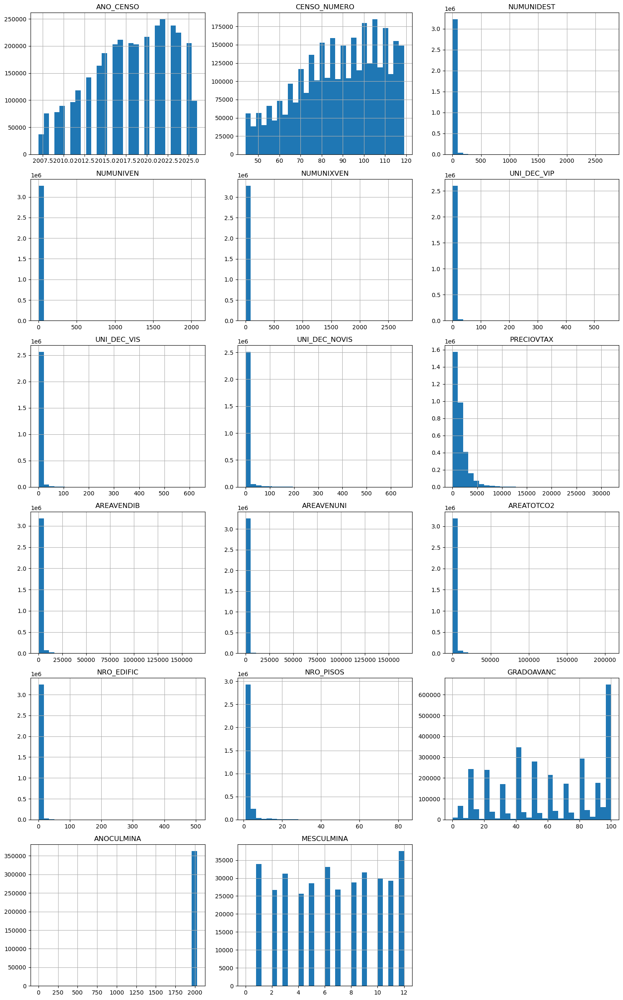

In [87]:
# Histogramas de las columnas numéricas
if numericas.shape[1] > 0:

    filas = math.ceil(numericas.shape[1] / 3)

    numericas.hist(figsize=(15, 4 * filas),bins=30,layout=(filas, 3)    )

    plt.tight_layout()
    plt.show()

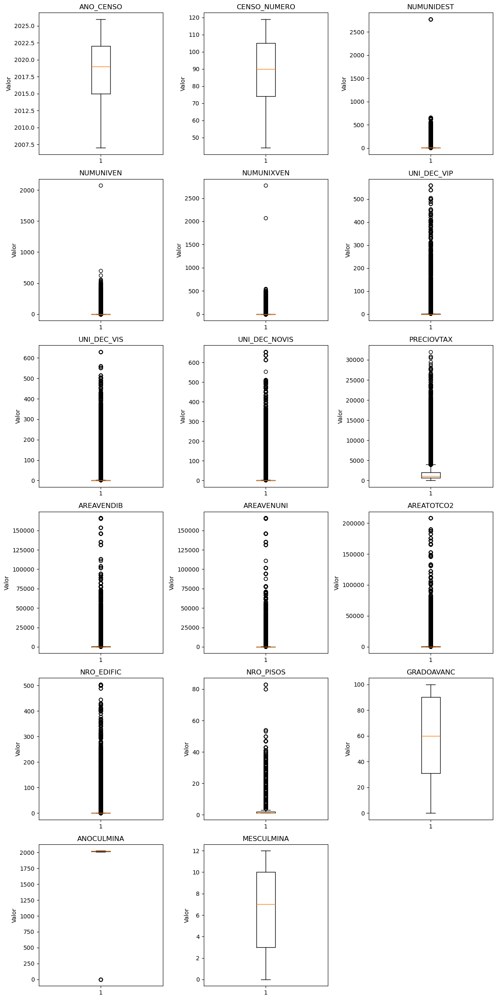

In [88]:
# Diagramas de caja por variable numérica
if numericas.shape[1] > 0:
    columnas = 3
    filas = math.ceil(numericas.shape[1] / columnas)

    plt.figure(figsize=(12, 4 * filas))

    for i, col in enumerate(numericas.columns):
        plt.subplot(filas, columnas, i + 1)
        plt.boxplot(numericas[col].dropna())
        plt.title(col)
        plt.ylabel("Valor")

    plt.tight_layout()
    plt.show()

**Para analizar:** ¿Cómo se distribuyen las variables? ¿Hay asimetrías, concentraciones o posibles valores atípicos? Un punto fuera del diagrama de caja no significa necesariamente un error.

## 6. Exploración de variables categóricas

Se identifican las frecuencias más frecuentes. Los gráficos muestran **hasta tres columnas categóricas** para que la salida no sea demasiado extensa; puedes cambiar `[:3]` según tu necesidad.

Para comprender correctamente como se distribuyen estas variables vamos a incluir sus nombres:

In [105]:
df_tratado2 = df_tratado.copy()

# 1. DESTINO DE LA EDIFICACIÓN

df_tratado2["DESTINO2"] = df_tratado["DESTINO2"].astype("string").replace({
    "1": "Apartamentos",
    "2": "Oficinas",
    "3": "Comercio",
    "4": "Casas",
    "5": "Bodegas",
    "6": "Educación",
    "7": "Hoteles",
    "8": "Hospitales y centros asistenciales",
    "9": "Administración pública",
    "10": "Otros"
}).astype("category")

# 2. ESTADO ACTUAL DE LA OBRA

df_tratado2["ESTADO_ACT"] = df_tratado["ESTADO_ACT"].astype("string").replace({
    "1": "En proceso",
    "2": "Paralizada completa",
    "3": "Culminada completa",
    "4": "Paralizada incompleta",
    "5": "Culminada incompleta",
    "6": "Demolida",
    "7": "Suspendida"
}).astype("category")

# 3. MOVIMIENTO DE LA OBRA

df_tratado2["MOVIMIENTO"] = df_tratado["MOVIMIENTO"].astype("string").replace({
    "N": "Obra nueva",
    "C": "Continúa en estado anterior",
    "F": "Reinicio después de suspensión",
    "I": "Paraliza actividad",
    "A": "Ampliación de cobertura",
    "R": "Reinicia actividad",
    "S": "Obra suspendida",
    "T": "Obra culminada",
    "D": "Obra demolida"
}).astype("category")

# 4. ESTRATO SOCIOECONÓMICO

df_tratado2["ESTRATO"] = df_tratado["ESTRATO"].astype("string").replace({
    "1": "Estrato 1",
    "2": "Estrato 2",
    "3": "Estrato 3",
    "4": "Estrato 4",
    "5": "Estrato 5",
    "6": "Estrato 6"
}).astype("category")

# 5. DESTINO PARA VENTA

df_tratado2["USO"] = df_tratado["USO"].astype("string").replace({
    "1": "Sí venta",
    "2": "No venta"
}).astype("category")


# 6. DESTINO CUANDO NO ES PARA VENTA

df_tratado2["USO_DOS"] = df_tratado["USO_DOS"].astype("string").replace({
    "1": "Arrendamiento",
    "2": "Donación",
    "3": "Uso propio"
}).astype("category")


# 7. PRECIO IMPUTADO DEL DESTINO

df_tratado2["TIPOVRDEST"] = df_tratado["TIPOVRDEST"].astype("string").replace({
    "1": "Sí",
    "2": "No",
    "5440": "Código 5440 (revisar)"
}).astype("category")

# 8. RANGO DE VALOR DE VIVIENDA

#Estos rangos están definidos en salarios mínimos de acuerdo con el municipio, por lo que inicialmente no se hace una inputación mas profunda.

df_tratado2["RANVIVI"] = df_tratado["RANVIVI"].astype("string").replace({
    "0": "Rango 0",
    "1": "Rango 1",
    "2": "Rango 2",
    "3": "Rango 3",
    "4": "Rango 4",
    "5": "Rango 5",
    "6": "Rango 6"
}).astype("category")

# 9. CAPÍTULO CONSTRUCTIVO

df_tratado2["CAPITULO"] = df_tratado["CAPITULO"].astype("string").replace({
    "1": "Excavación y cimentación",
    "2": "Estructura y cubierta",
    "3": "Mampostería y pañete",
    "4": "Acabados nivel 1",
    "5": "Acabados nivel 2",
    "6": "Acabados nivel 3"
}).astype("category")


# ==========================================
# VERIFICAR RESULTADO
# ==========================================

columnas_categoricas = [
    "DESTINO2", "ESTADO_ACT", "MOVIMIENTO",
    "ESTRATO", "USO", "USO_DOS",
    "TIPOVRDEST", "RANVIVI", "CAPITULO"
]

display(df_tratado2[columnas_categoricas].head(10))

print(df_tratado2[columnas_categoricas].dtypes)


,DESTINO2,ESTADO_ACT,MOVIMIENTO,ESTRATO,USO,USO_DOS,TIPOVRDEST,RANVIVI,CAPITULO
0,Apartamentos,En proceso,Continúa en estado anterior,Estrato 6,Sí venta,<NA>,No,Rango 6,Estructura y cubierta
1,Bodegas,En proceso,Continúa en estado anterior,Estrato 4,No venta,Uso propio,Sí,Rango 0,Acabados nivel 2
2,Casas,Paralizada incompleta,Continúa en estado anterior,Estrato 3,No venta,Uso propio,No,Rango 3,Mampostería y pañete
3,Casas,En proceso,Continúa en estado anterior,Estrato 2,No venta,Uso propio,Sí,Rango 1,Mampostería y pañete
4,Casas,En proceso,Continúa en estado anterior,Estrato 6,Sí venta,<NA>,Sí,Rango 5,Mampostería y pañete
5,Apartamentos,En proceso,Continúa en estado anterior,Estrato 5,Sí venta,<NA>,No,Rango 5,Acabados nivel 1
6,Casas,Culminada completa,Obra culminada,Estrato 2,No venta,Uso propio,Sí,Rango 2,Acabados nivel 3
7,Comercio,En proceso,Continúa en estado anterior,Estrato 4,No venta,Uso propio,Sí,Rango 0,Mampostería y pañete
8,Apartamentos,En proceso,Continúa en estado anterior,Estrato 6,Sí venta,<NA>,No,Rango 6,Estructura y cubierta
9,Comercio,En proceso,Continúa en estado anterior,Estrato 3,No venta,Uso propio,Sí,Rango 0,Acabados nivel 1


DESTINO2      category
ESTADO_ACT    category
MOVIMIENTO    category
ESTRATO       category
USO           category
USO_DOS       category
TIPOVRDEST    category
RANVIVI       category
CAPITULO      category
dtype: object


Para nombrar los municipios vamos a cargar la base con los nombre y códigos:

In [122]:
MUNI= pd.read_excel("BaseMunicipiosDIVIPOLA.xlsx")

MUNI.head()

,cod_depto,cod_muni,DEPTO+MPIO,Departamento,Municipio,cobertura
0,5,1,5001,Antioquia,Medellín,77
1,5,79,5079,Antioquia,Barbosa,77
2,5,88,5088,Antioquia,Bello,77
3,5,129,5129,Antioquia,Caldas,77
4,5,212,5212,Antioquia,Copacabana,77


In [ ]:
# Asegurar que los códigos tengan el mismo formato
df_tratado2["DPTO_MPIO"] = df_tratado2["DPTO_MPIO"].astype("string").str.zfill(5)
MUNI["DEPTO+MPIO"] = MUNI["DEPTO+MPIO"].astype("string").str.zfill(5)

# Cruzar las tablas
df_tratado2 = df_tratado2.merge(
    MUNI[["DEPTO+MPIO", "DEPARTAMENTO", "MUNICIPIO"]].drop_duplicates(),
    left_on="DPTO_MPIO",
    right_on="DEPTO+MPIO",
    how="left",
    validate="many_to_one"
)

# Eliminar la columna duplicada del código
df_tratado2 = df_tratado2.drop(columns="DEPTO+MPIO")

# Verificar resultado
display(df_tratado2[["DPTO_MPIO", "Departamento", "Municipio"]].head(10))


,DPTO_MPIO,Departamento,Municipio
0,13001,Bolívar,Cartagena de Indias
1,17001,Caldas,Manizales
2,19001,Cauca,Popayán
3,41001,Huila,Neiva
4,50001,Meta,Villavicencio
5,52001,Nariño,Pasto
6,54874,Norte de Santander,Villa del Rosario
7,73001,Tolima,Ibagué
8,13001,Bolívar,Cartagena de Indias
9,17001,Caldas,Manizales


In [124]:
print("Registros originales:", len(df_tratado))
print("Registros después del cruce:", len(df_tratado2))

print("Municipios sin identificar:",
      df_tratado2["Municipio"].isna().sum())

Registros originales: 3278092
Registros después del cruce: 3278092
Municipios sin identificar: 34577


In [125]:
df_tratado2.loc[
    df_tratado2["Municipio"].isna(),
    "DPTO_MPIO"
].value_counts()

DPTO_MPIO
00000    34577
Name: count, dtype: Int64

Se identifica que algunos municipios están identificados con el código código 00000 que no corresponde a un municipio válido dentro de la codificación DIVIPOLA habitual, dado que sólo corresponde al 1.05% de los registros, se podría considerar eliminarnos.

In [126]:
pd.crosstab(
    df_tratado2["ANO_CENSO"],
    df_tratado2["DPTO_MPIO"] == "00000"
)

DPTO_MPIO,False,True
ANO_CENSO,,
2007,36564,318
2008,74961,750
2009,76859,789
2010,88848,745
2011,95293,709
2012,116428,1228
2013,140188,1640
2014,161747,1480
2015,185029,1501


No se concentran en un año específico

In [132]:
categoricas = df_tratado2.select_dtypes(include=["object", "category", "bool", "string"]).drop(columns=["CONS_ID","NOFORMULAR","DPTO_MPIO"])

In [134]:
categoricas.columns

Index(['TRIMESTRE', 'DESTINO2', 'ESTADO_ACT', 'MOVIMIENTO', 'ESTRATO', 'USO',
       'USO_DOS', 'TIPOVRDEST', 'RANVIVI', 'CAPITULO', 'Departamento',
       'Municipio'],
      dtype='object')

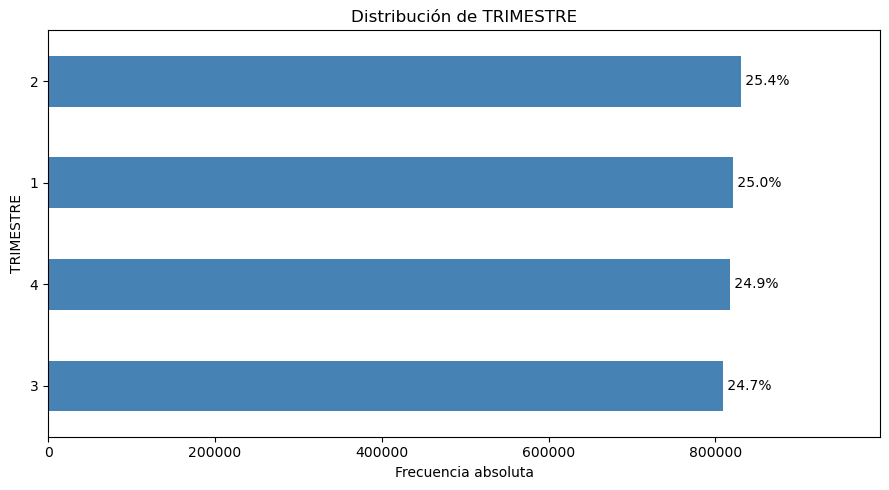

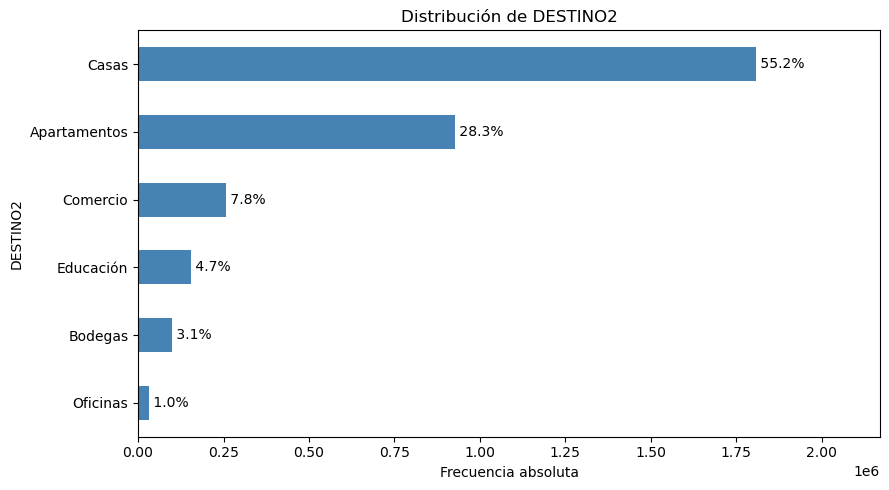

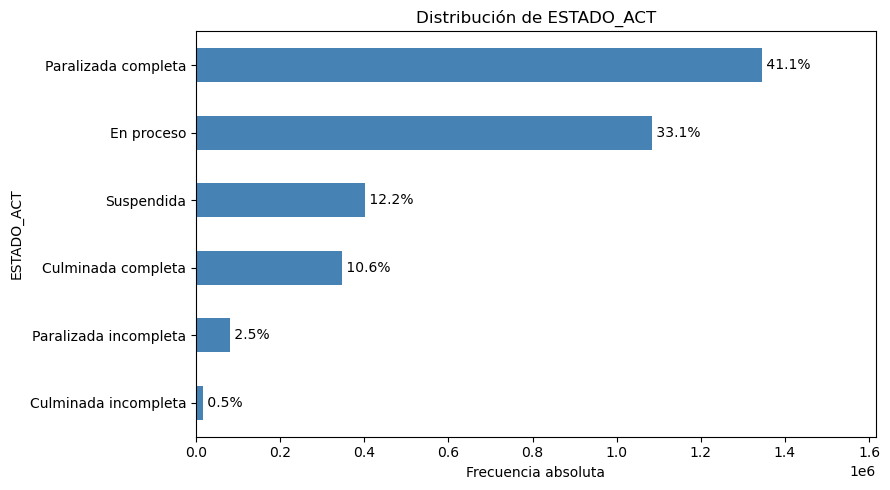

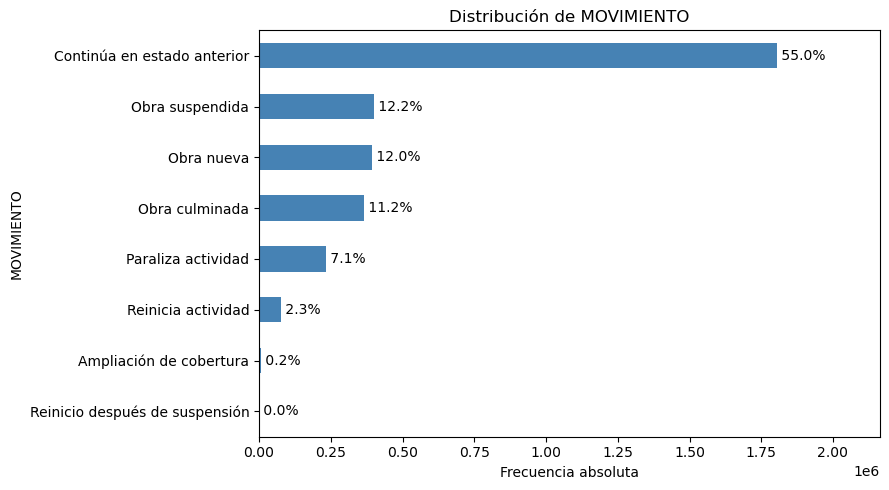

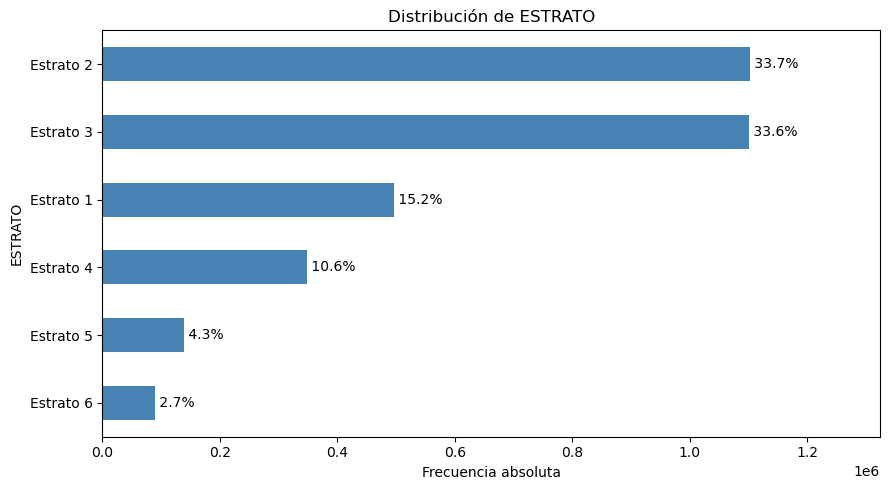

...

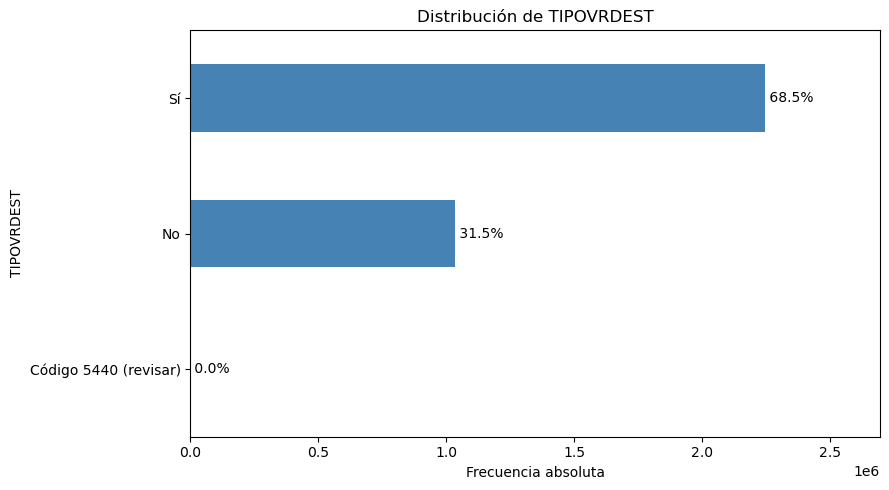

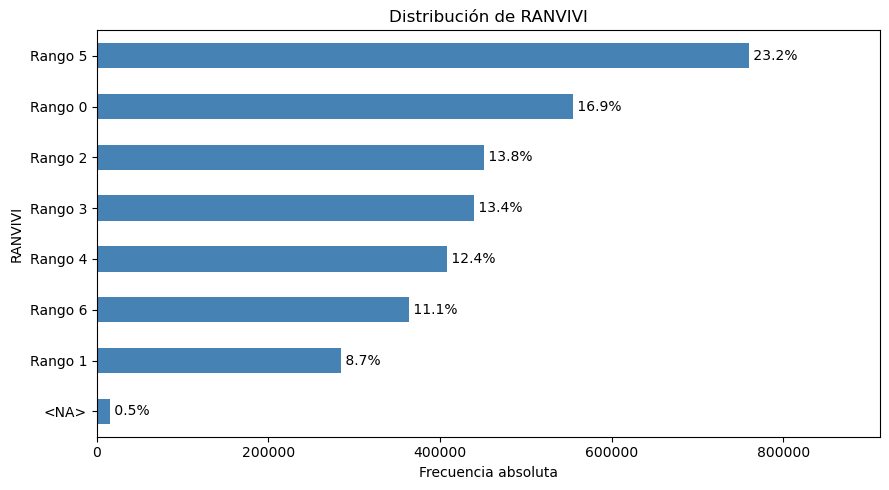

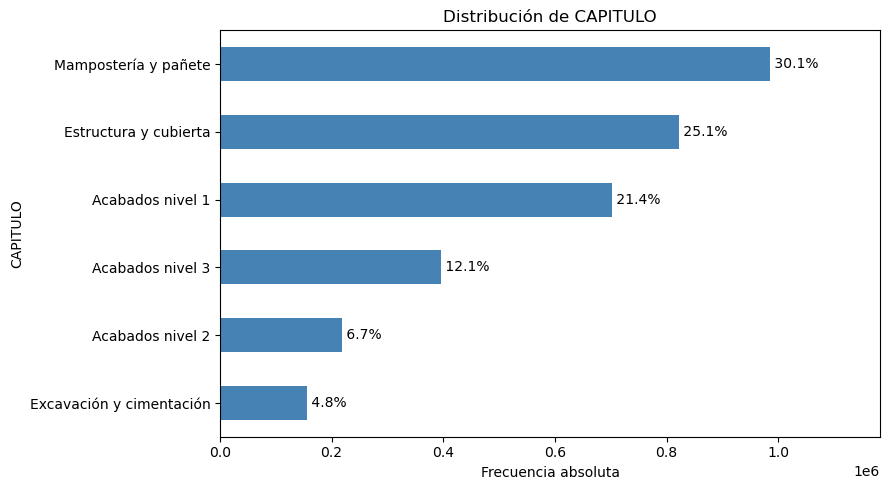

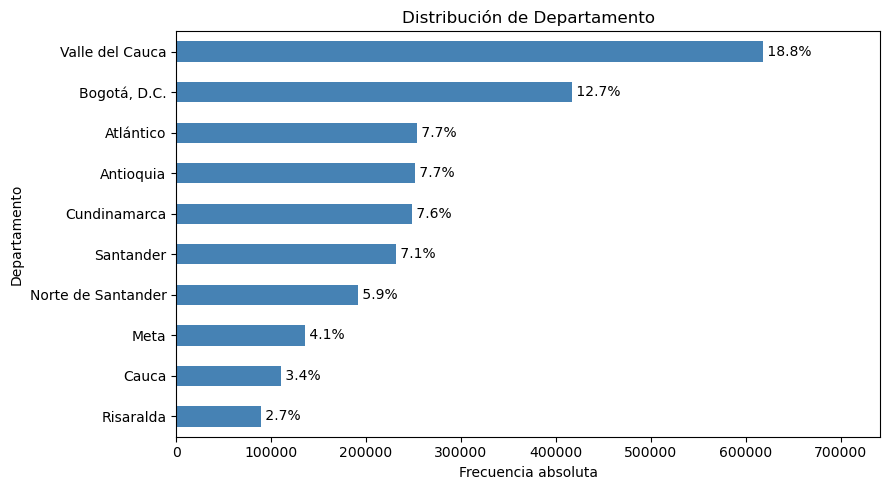

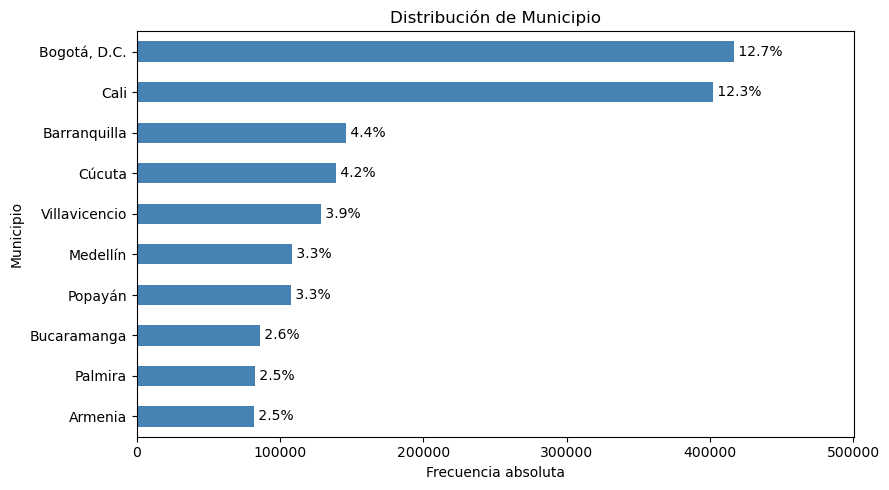

In [135]:
for col in categoricas.columns:

    frecuencias = df_tratado2[col].value_counts(
        dropna=False
    ).head(10).sort_values()

    ax = frecuencias.plot(
        kind="barh",
        figsize=(9, 5),
        color="steelblue"
    )

    # Agregar porcentajes al final de cada barra
    for i, valor in enumerate(frecuencias):
        porcentaje = (valor / len(df_tratado2)) * 100
        ax.text(valor, i, f" {porcentaje:.1f}%", va="center")

    plt.title(f"Distribución de {col}")
    plt.xlabel("Frecuencia absoluta")
    plt.ylabel(col)
    plt.xlim(0, frecuencias.max() * 1.20)
    plt.tight_layout()
    plt.show()


Tabla cruzada: TRIMESTRE vs DESTINO2


DESTINO2,1,2,3,4,5,6
TRIMESTRE,,,,,,
1,28.36,1.02,7.84,55.02,3.06,4.70
2,28.60,1.01,7.84,54.82,3.08,4.64
3,27.87,1.02,7.75,55.64,3.06,4.67
4,28.18,1.02,7.81,55.19,3.05,4.75


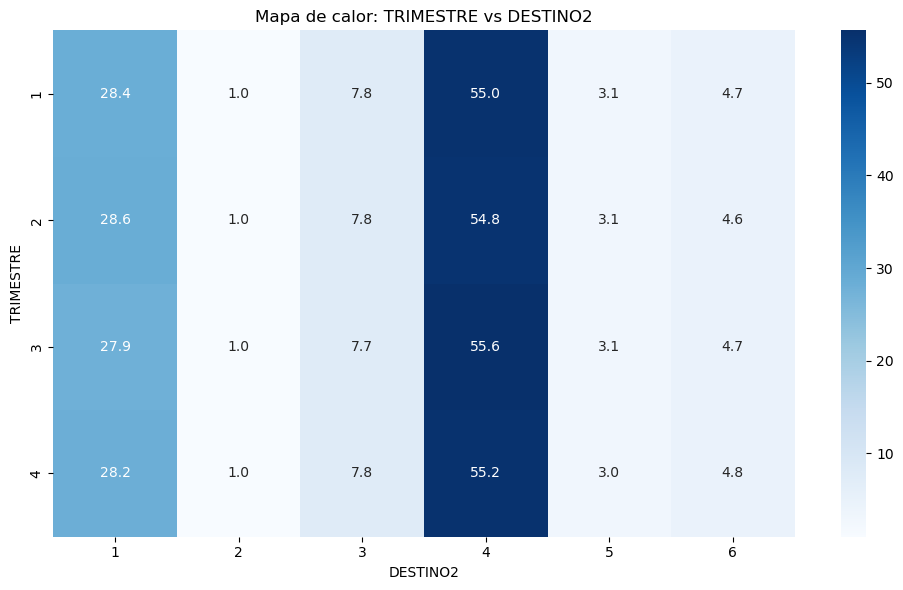


Tabla cruzada: TRIMESTRE vs ESTADO_ACT


ESTADO_ACT,1,2,3,4,5,7
TRIMESTRE,,,,,,
1,33.21,41.03,10.41,2.42,0.61,12.32
2,33.10,41.48,10.30,2.46,0.62,12.03
3,33.45,40.80,10.50,2.51,0.46,12.26
4,32.56,40.94,11.24,2.48,0.48,12.31


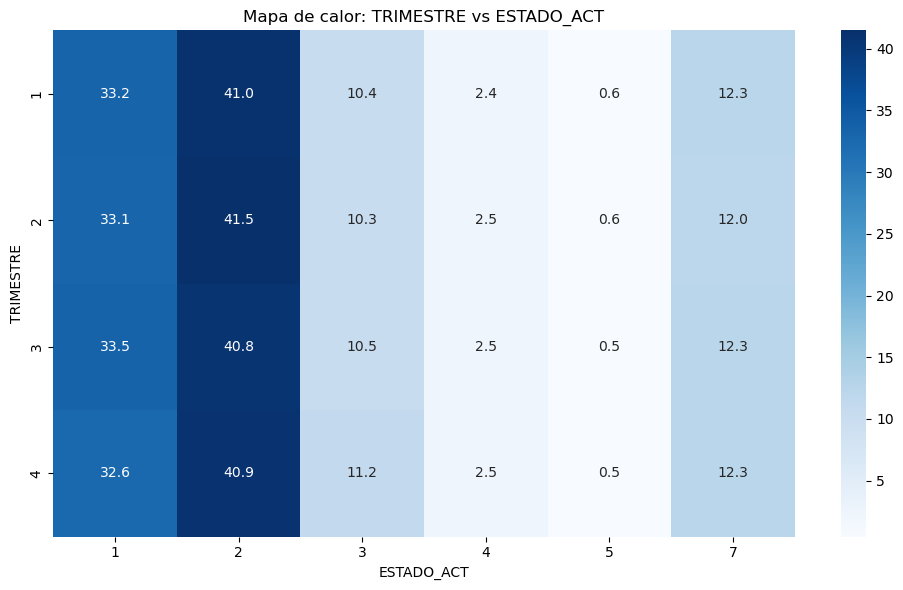


Tabla cruzada: TRIMESTRE vs MOVIMIENTO


MOVIMIENTO,A,C,F,I,N,R,S,T
TRIMESTRE,,,,,,,,
1,0.18,55.18,0.01,6.86,12.16,2.28,12.32,11.02
2,0.20,54.98,0.01,7.49,12.12,2.24,12.03,10.92
3,0.23,55.08,0.01,7.02,11.94,2.49,12.26,10.97
4,0.13,54.78,0.01,7.22,11.67,2.16,12.31,11.72


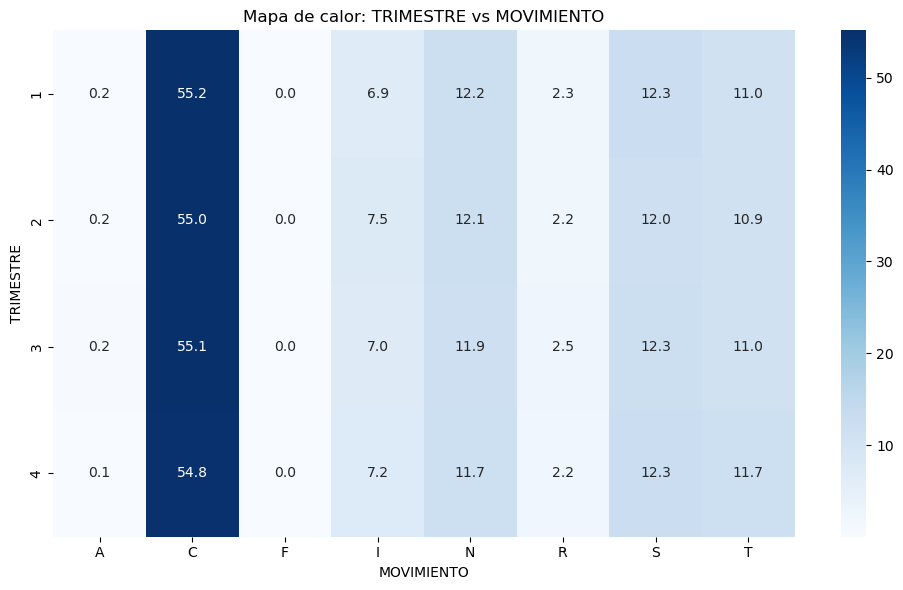


Tabla cruzada: TRIMESTRE vs ESTRATO


ESTRATO,1,2,3,4,5,6
TRIMESTRE,,,,,,
1,15.22,33.69,33.53,10.58,4.25,2.73
2,15.24,33.74,33.49,10.58,4.24,2.71
3,15.07,33.57,33.67,10.64,4.27,2.78
4,15.10,33.61,33.64,10.63,4.27,2.75


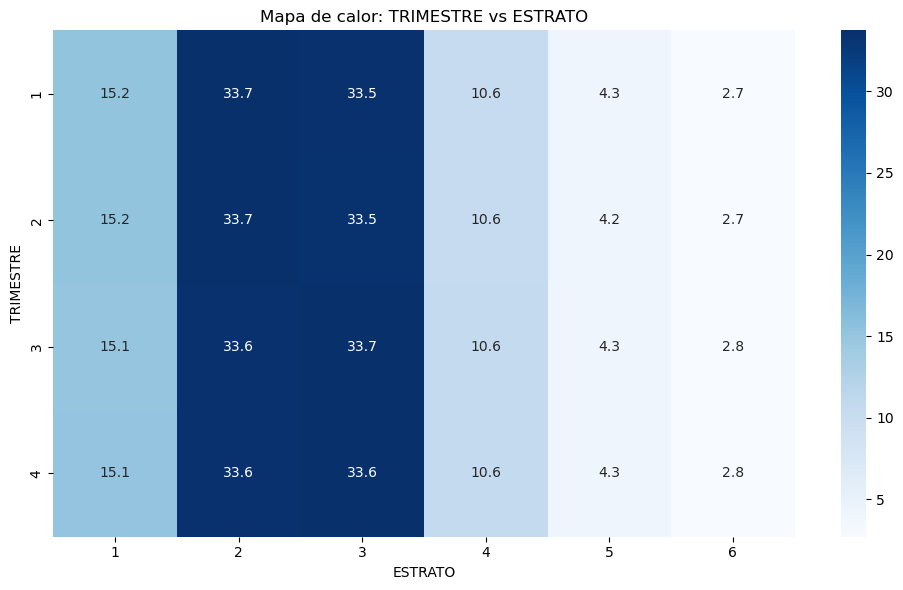


Tabla cruzada: TRIMESTRE vs USO


USO,1,2
TRIMESTRE,,
1,16.51,83.49
2,16.57,83.43
3,16.59,83.41
4,16.64,83.36


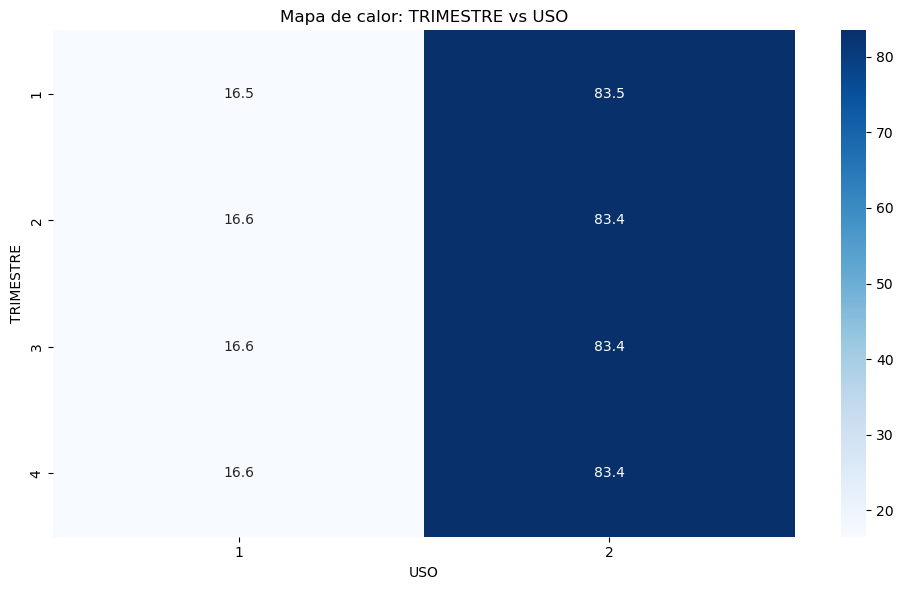


Tabla cruzada: TRIMESTRE vs USO_DOS


USO_DOS,1,2,3
TRIMESTRE,,,
1,22.23,0.36,77.42
2,22.64,0.36,76.99
3,21.28,0.37,78.34
4,21.84,0.35,77.81


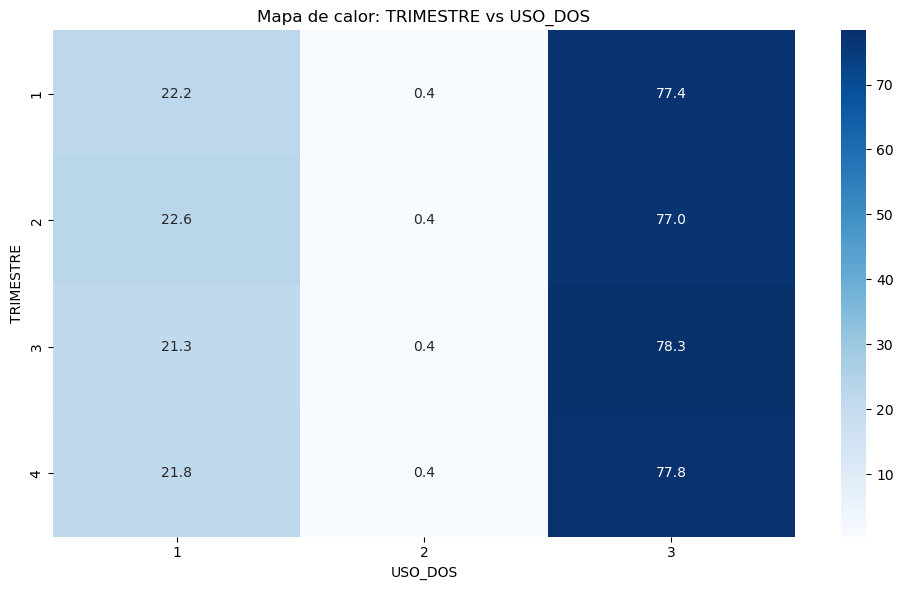


Tabla cruzada: TRIMESTRE vs TIPOVRDEST


TIPOVRDEST,1,2,5440
TRIMESTRE,,,
1,68.77,31.23,0.0
2,68.74,31.26,0.0
3,67.96,32.04,0.0
4,68.40,31.60,0.0


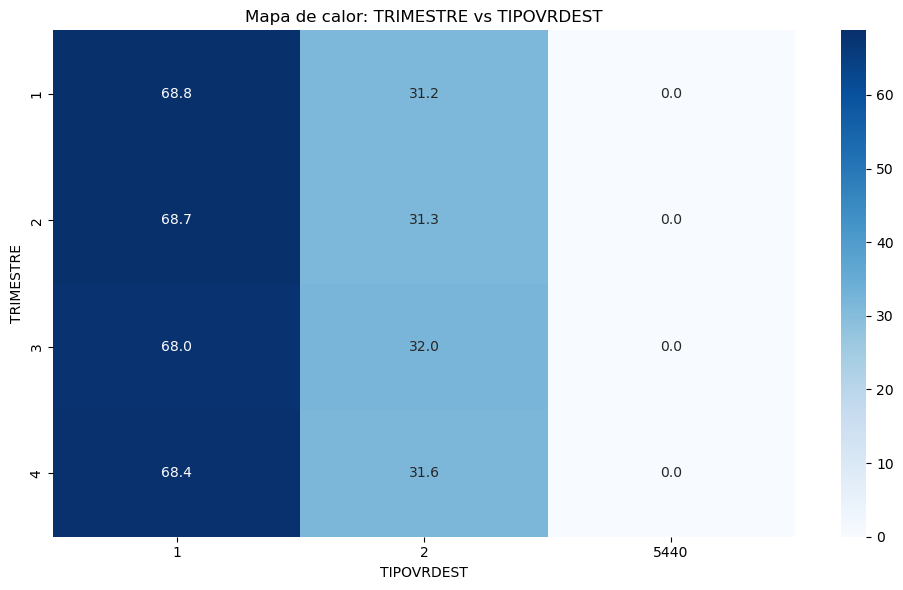


Tabla cruzada: TRIMESTRE vs RANVIVI


RANVIVI,0,1,2,3,4,5,6
TRIMESTRE,,,,,,,
1,17.05,8.70,13.87,13.49,12.49,23.29,11.12
2,16.93,8.70,13.96,13.48,12.53,23.25,11.14
3,16.94,8.82,13.76,13.48,12.53,23.28,11.19
4,17.04,8.67,13.73,13.47,12.47,23.42,11.19


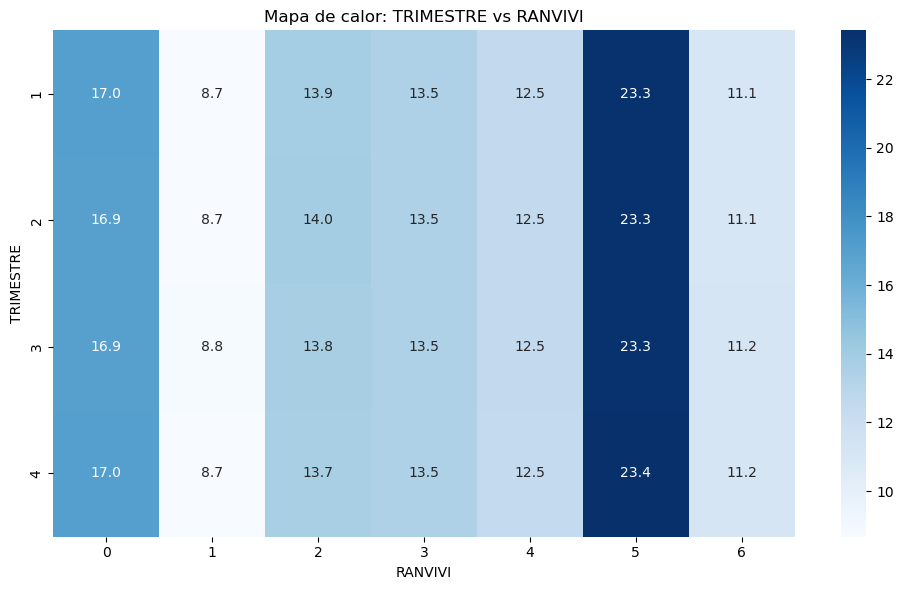


Tabla cruzada: TRIMESTRE vs CAPITULO


CAPITULO,1,2,3,4,5,6
TRIMESTRE,,,,,,
1,4.89,25.10,30.00,21.43,6.68,11.90
2,4.87,25.48,30.06,21.26,6.58,11.75
3,4.72,25.04,30.06,21.47,6.75,11.96
4,4.52,24.60,30.10,21.45,6.71,12.61


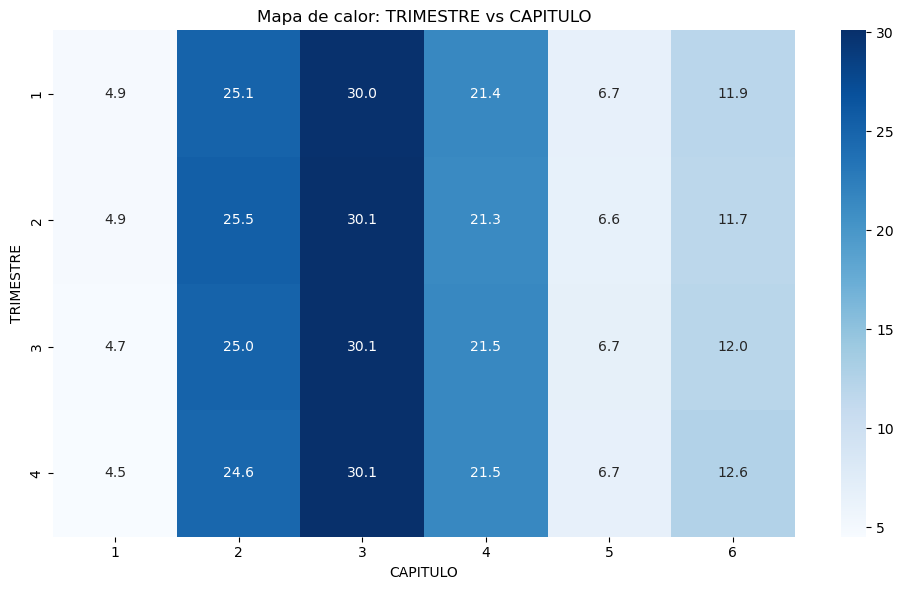


Tabla cruzada: TRIMESTRE vs Departamento


KeyError: 'Departamento'

In [ ]:
#Se eliminan estas dos variables dado que para el análisis cruzado municipios no es fácil de gráficas se reemplaza inicialmente con departamente y 
# cobertura no aporta información para análisis relevente

categoricas2 = categoricas.drop(columns=["Departamento","Municipio"])

# Cruzar todas las variables categóricas entre sí
for var1, var2 in combinations(categoricas2.columns, 2):

    print(f"\nTabla cruzada: {var1} vs {var2}")

    # Tabla cruzada en porcentajes por fila
    tabla = pd.crosstab(
        df_tratado2[var1],
        df_tratado2[var2],
        normalize="index",
        dropna=False
    ) * 100

    # Mostrar tabla
    display(tabla.round(2))

    # Mapa de calor
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        tabla,
        annot=True,
        fmt=".1f",
        cmap="Blues"
    )
    plt.title(f"Mapa de calor: {var1} vs {var2}")
    plt.xlabel(var2)
    plt.ylabel(var1)
    plt.tight_layout()
    plt.show()


Tabla cruzada: Departamento vs TRIMESTRE


TRIMESTRE,1,2,3,4
Departamento,,,,
NaN,25.25,25.40,24.50,24.85
Antioquia,25.04,25.25,24.82,24.89
Atlántico,25.01,25.31,24.81,24.87
"Bogotá, D.C.",24.81,25.10,25.04,25.05
Bolívar,25.21,25.45,24.63,24.71
Boyacá,25.78,26.21,23.09,24.92
Caldas,24.94,25.25,24.93,24.88
Caquetá,25.34,25.62,23.82,25.22
Casanare,25.77,26.55,22.94,24.74


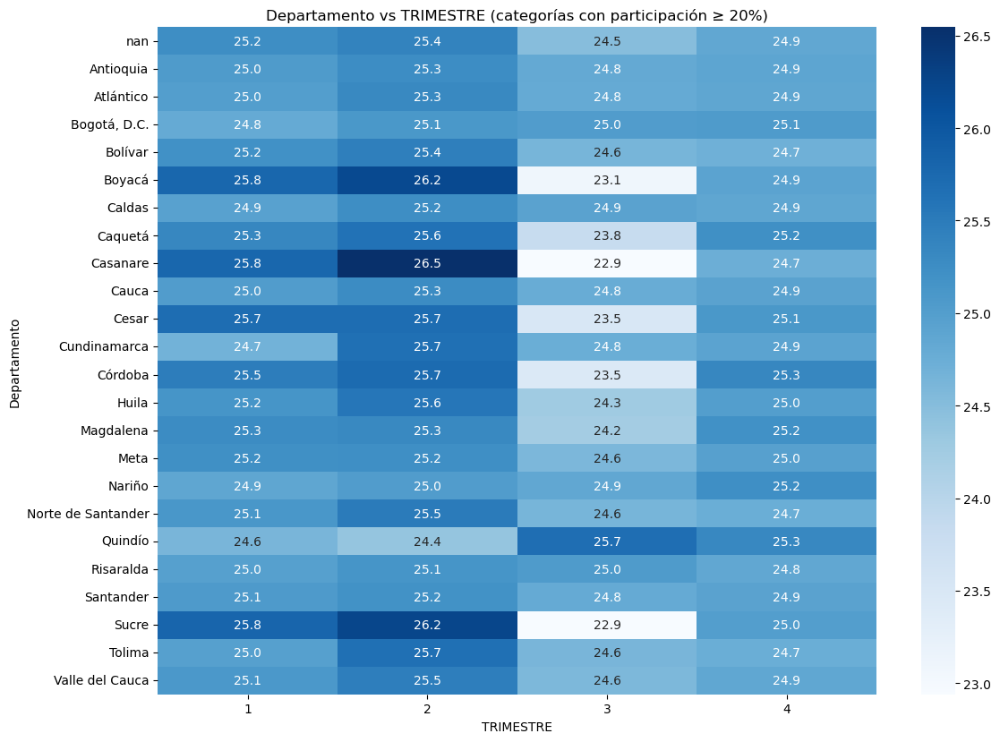


Tabla cruzada: Departamento vs DESTINO2


DESTINO2,Apartamentos,Casas,Comercio
Departamento,,,
NaN,25.44,21.10,27.55
Antioquia,54.51,18.41,15.47
Atlántico,38.42,43.76,6.89
"Bogotá, D.C.",26.96,48.51,8.81
Bolívar,29.22,48.79,7.96
Boyacá,45.90,35.89,12.89
Caldas,21.92,64.43,6.96
Caquetá,16.21,69.98,7.08
Casanare,21.92,63.86,7.30


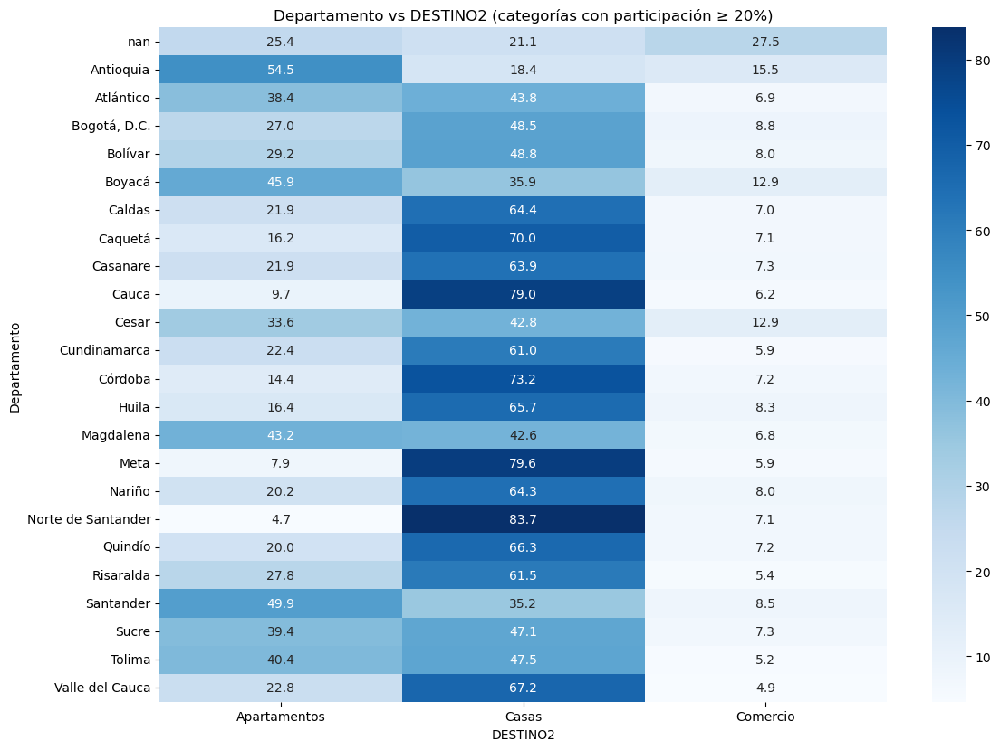


Tabla cruzada: Departamento vs ESTADO_ACT


ESTADO_ACT,En proceso,Paralizada completa,Suspendida
Departamento,,,
NaN,50.02,35.64,3.90
Antioquia,49.95,30.32,3.71
Atlántico,27.73,48.15,12.67
"Bogotá, D.C.",42.01,32.24,8.07
Bolívar,36.25,45.81,5.26
Boyacá,43.31,38.68,3.00
Caldas,35.28,41.23,8.70
Caquetá,33.31,51.97,0.00
Casanare,31.16,54.02,0.00


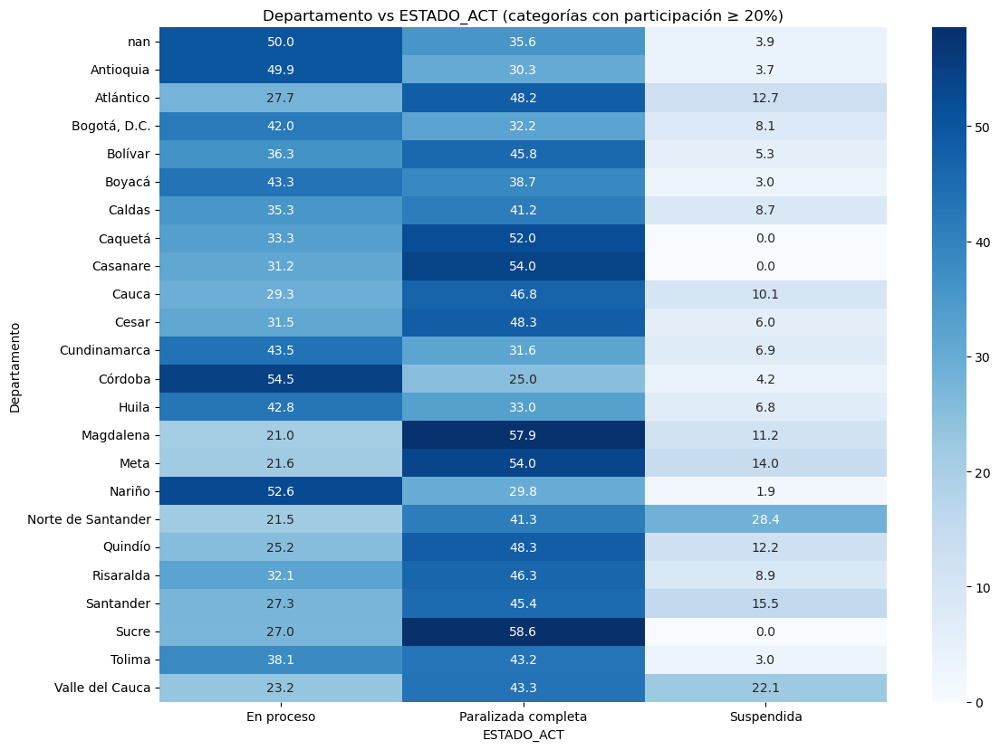


Tabla cruzada: Departamento vs MOVIMIENTO


MOVIMIENTO,Continúa en estado anterior,Obra suspendida
Departamento,,
NaN,65.74,3.90
Antioquia,58.58,3.71
Atlántico,58.25,12.67
"Bogotá, D.C.",54.33,8.07
Bolívar,61.41,5.26
Boyacá,64.58,3.00
Caldas,54.18,8.70
Caquetá,57.59,0.00
Casanare,55.85,0.00


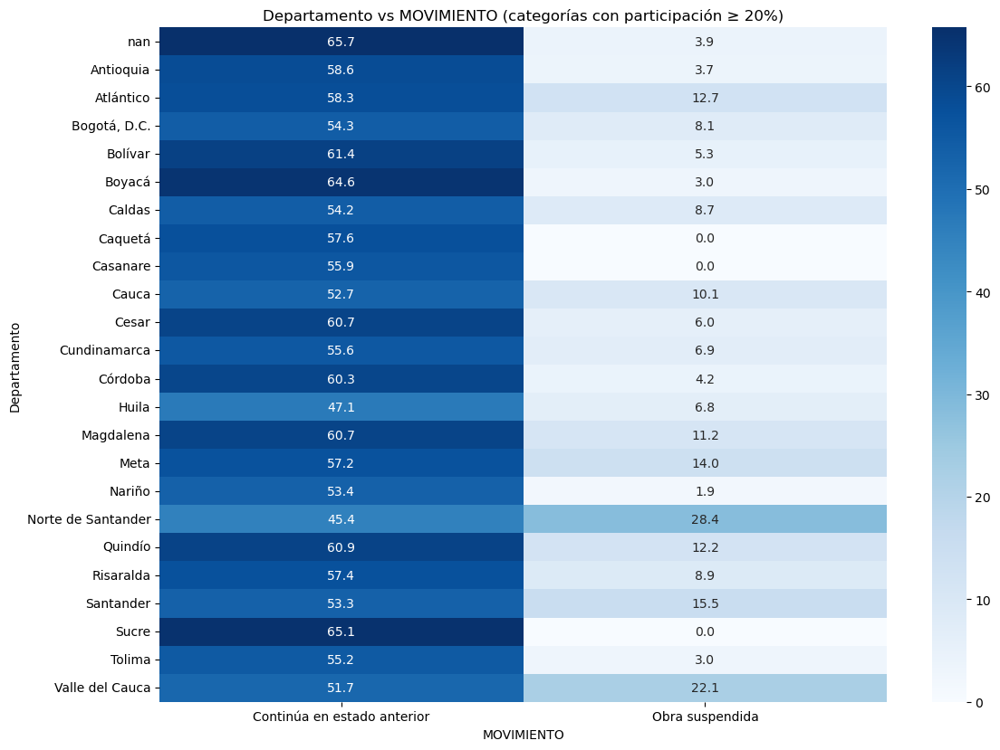


Tabla cruzada: Departamento vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4
Departamento,,,,
NaN,5.60,24.93,40.89,18.48
Antioquia,2.40,14.88,46.87,20.24
Atlántico,21.97,40.74,22.20,7.55
"Bogotá, D.C.",10.22,35.32,38.96,7.98
Bolívar,9.82,34.10,29.13,14.84
Boyacá,1.36,29.91,52.89,10.03
Caldas,13.35,34.07,34.27,11.05
Caquetá,53.76,17.65,23.32,5.15
Casanare,29.67,51.82,14.53,3.61


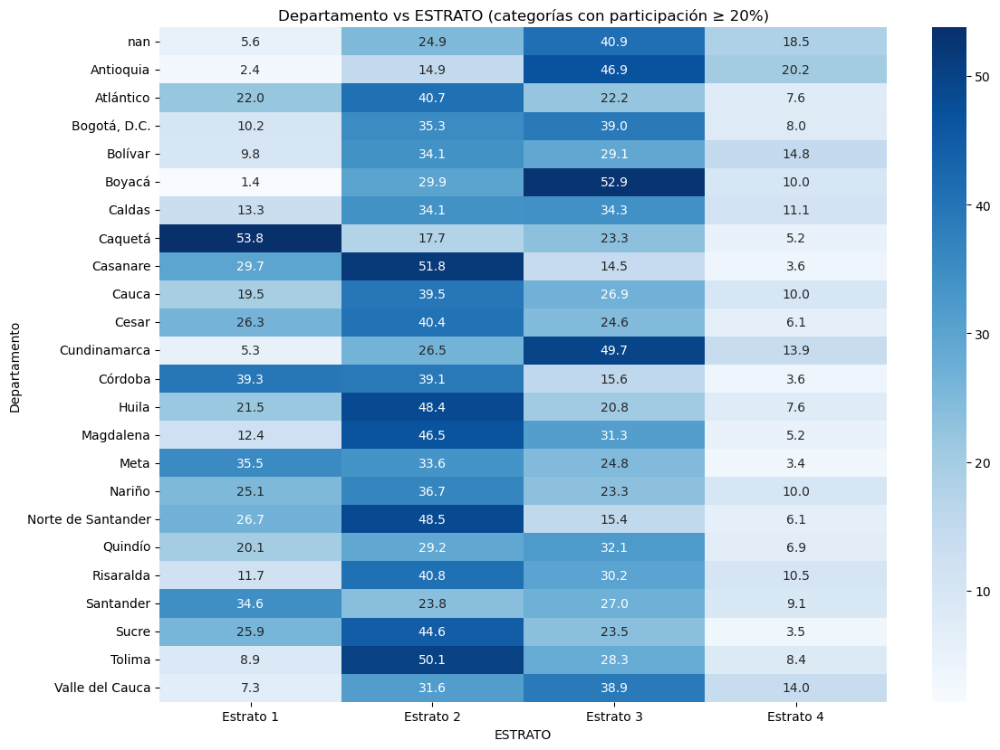


Tabla cruzada: Departamento vs USO


USO,No venta,Sí venta
Departamento,,
NaN,59.85,40.15
Antioquia,67.90,32.10
Atlántico,85.48,14.52
"Bogotá, D.C.",78.57,21.43
Bolívar,78.73,21.27
Boyacá,69.68,30.32
Caldas,83.82,16.18
Caquetá,90.00,10.00
Casanare,91.10,8.90


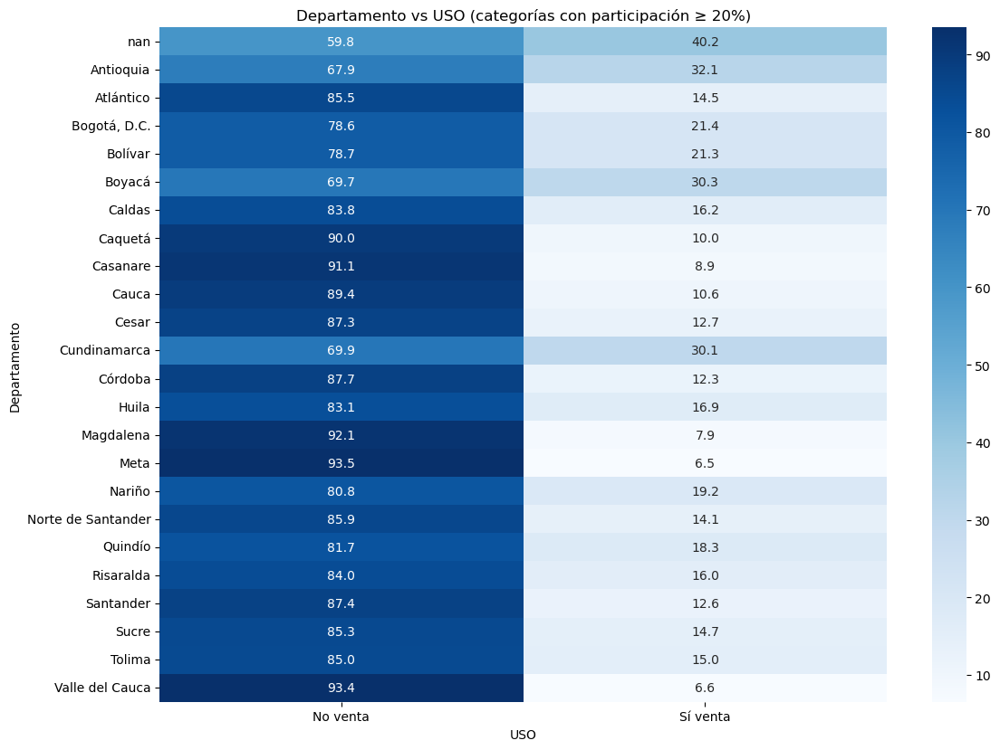


Tabla cruzada: Departamento vs USO_DOS


USO_DOS,Arrendamiento,Uso propio
Departamento,,
NaN,43.40,56.15
Antioquia,30.57,68.52
Atlántico,28.53,71.06
"Bogotá, D.C.",17.33,82.46
Bolívar,21.09,78.16
Boyacá,50.88,49.09
Caldas,8.92,90.33
Caquetá,23.35,76.10
Casanare,14.83,84.24


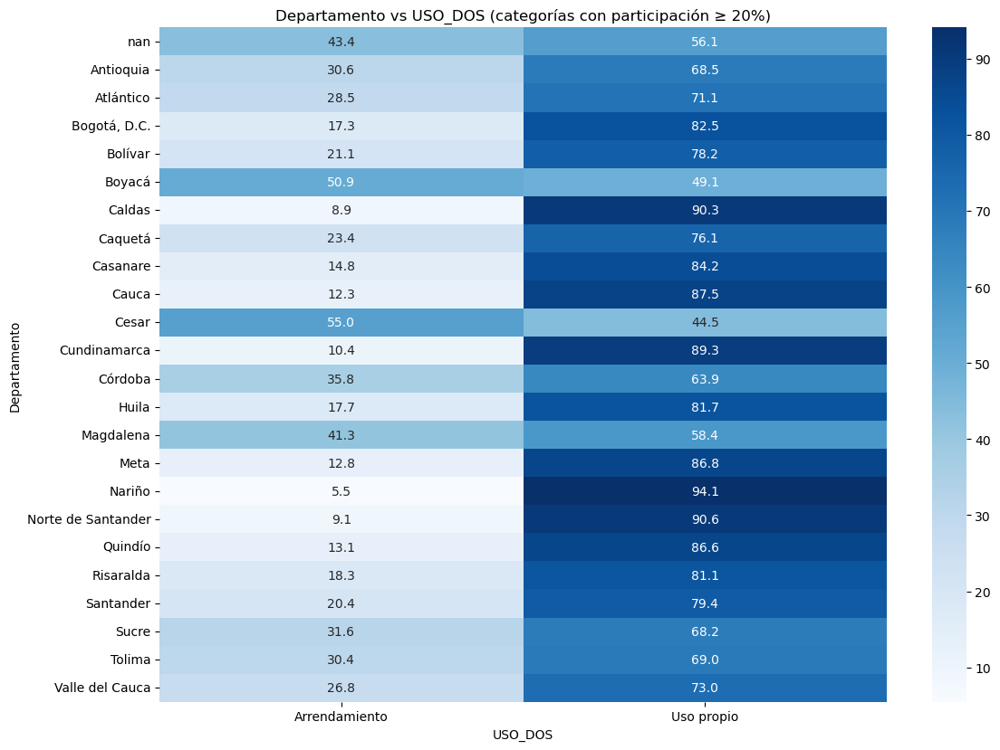


Tabla cruzada: Departamento vs TIPOVRDEST


TIPOVRDEST,No,Sí
Departamento,,
NaN,16.15,83.85
Antioquia,15.19,84.81
Atlántico,27.59,72.41
"Bogotá, D.C.",36.91,63.09
Bolívar,35.44,64.56
Boyacá,2.24,97.76
Caldas,11.93,88.07
Caquetá,2.40,97.60
Casanare,6.94,93.06


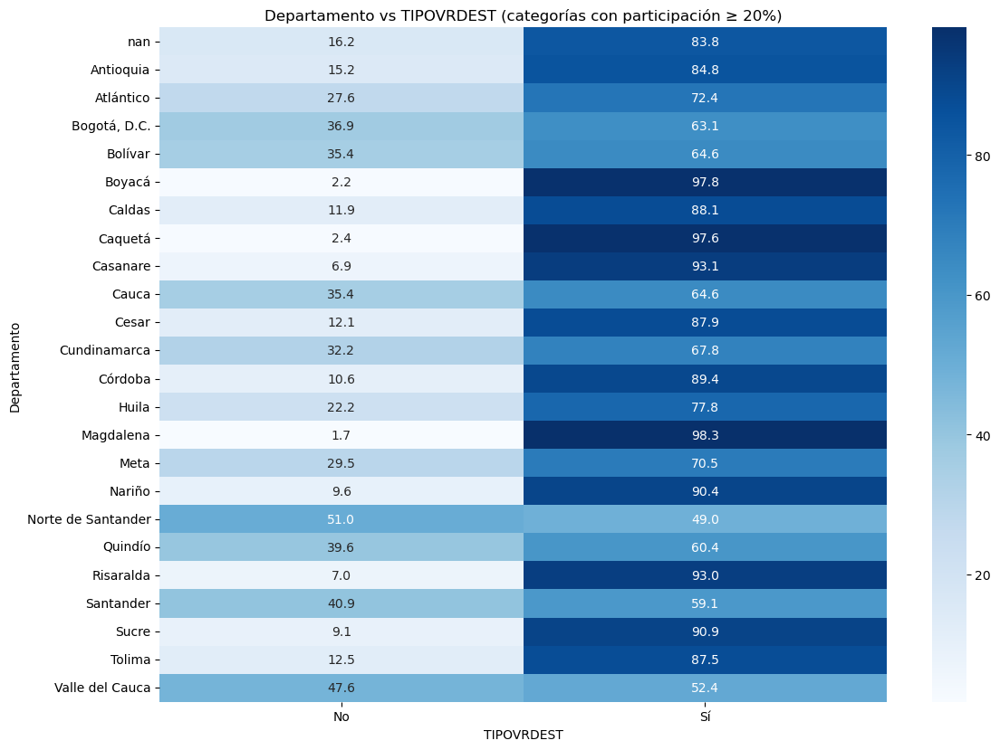


Tabla cruzada: Departamento vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 5,Rango 6
Departamento,,,,,,
NaN,53.45,1.16,4.27,4.02,17.05,14.55
Antioquia,27.42,1.25,3.90,6.12,31.84,20.21
Atlántico,18.33,9.89,17.81,15.59,16.93,7.70
"Bogotá, D.C.",25.17,5.47,7.55,7.99,27.04,17.45
Bolívar,21.98,2.24,8.03,10.30,26.60,18.24
Boyacá,18.28,0.14,3.48,4.46,47.52,14.27
Caldas,13.65,20.40,16.73,11.03,21.36,6.74
Caquetá,13.94,12.38,27.97,8.33,25.01,4.22
Casanare,14.27,9.46,25.74,13.04,20.80,5.95


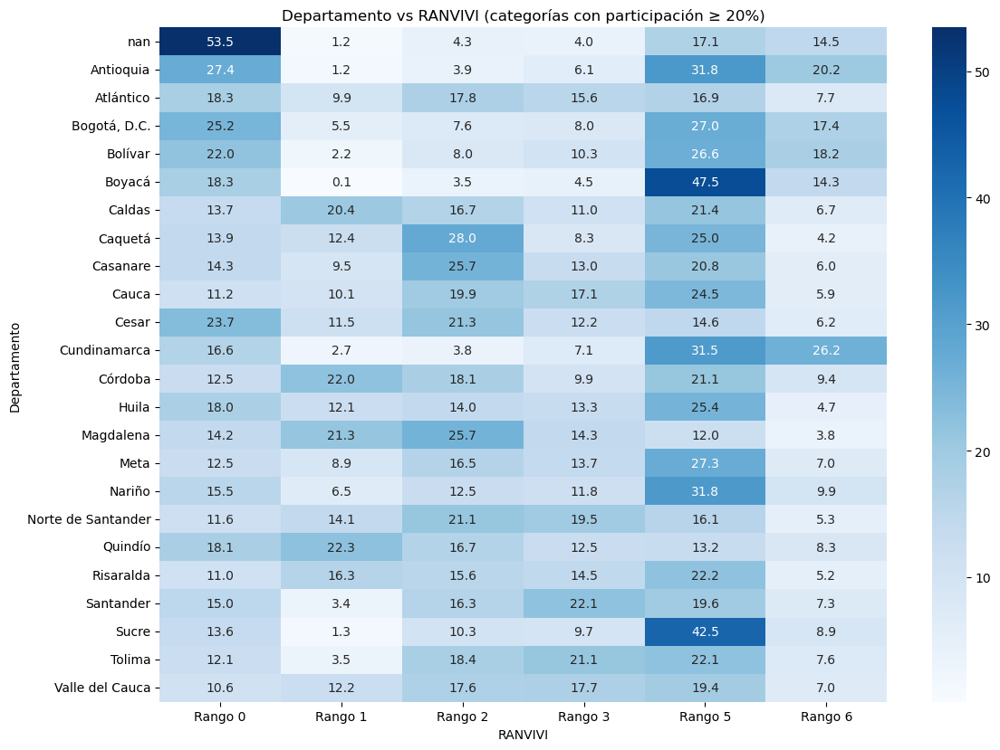


Tabla cruzada: Departamento vs CAPITULO


CAPITULO,Acabados nivel 1,Estructura y cubierta,Mampostería y pañete
Departamento,,,
NaN,17.25,33.14,21.08
Antioquia,14.96,33.82,24.01
Atlántico,22.91,21.75,36.73
"Bogotá, D.C.",12.89,33.87,24.39
Bolívar,22.06,25.40,28.27
Boyacá,15.21,37.33,22.18
Caldas,18.48,23.62,35.15
Caquetá,26.26,21.68,26.91
Casanare,29.98,20.80,28.17


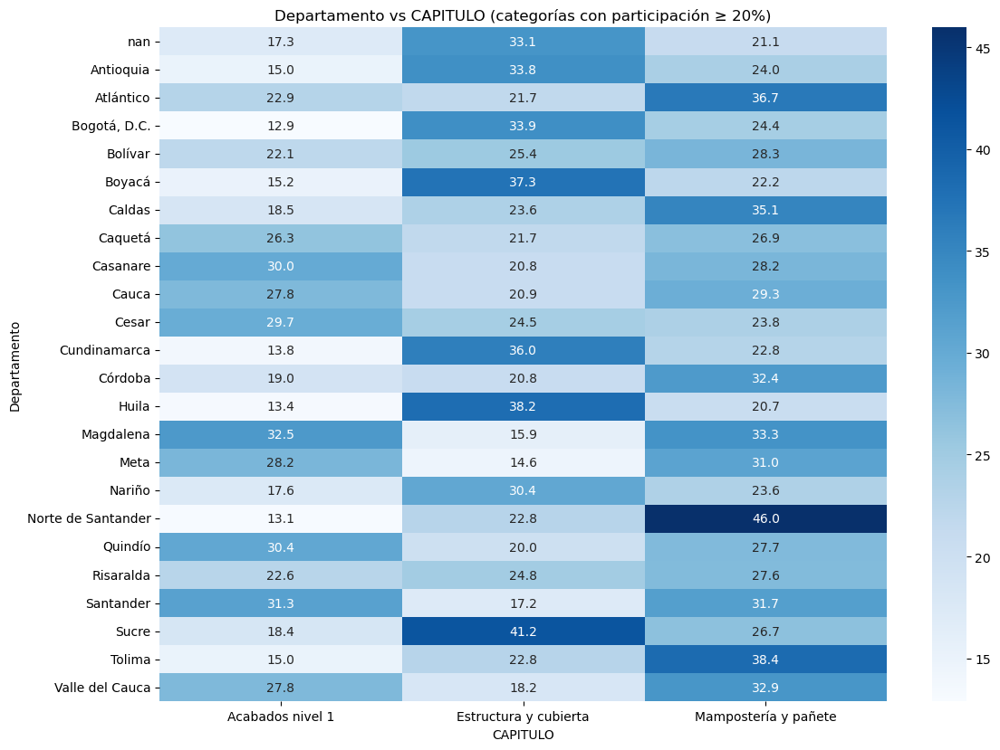


Tabla cruzada: Municipio vs TRIMESTRE


TRIMESTRE,1,2,3,4
Municipio,,,,
NaN,25.25,25.40,24.50,24.85
Acacías,25.64,26.14,23.67,24.54
Armenia,24.63,24.37,25.68,25.32
Barbosa,25.17,24.98,24.56,25.29
Barranquilla,24.99,25.15,24.97,24.88
Bello,25.26,24.95,24.83,24.96
"Bogotá, D.C.",24.81,25.10,25.04,25.05
Bucaramanga,24.91,24.92,25.13,25.04
Cajicá,25.21,25.60,24.31,24.88


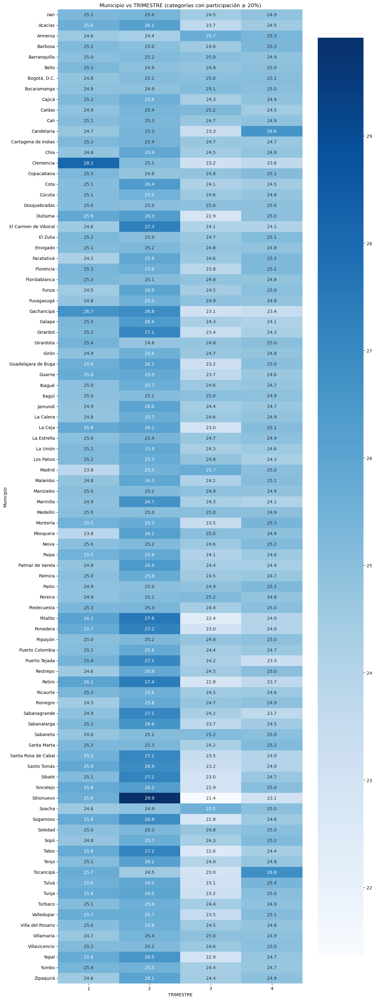


Tabla cruzada: Municipio vs DESTINO2


DESTINO2,Apartamentos,Bodegas,Casas,Comercio,Educación
Municipio,,,,,
NaN,25.44,16.25,21.10,27.55,1.41
Acacías,19.30,3.82,65.36,9.27,2.04
Armenia,19.99,1.77,66.26,7.18,4.02
Barbosa,74.32,0.19,3.78,14.48,7.22
Barranquilla,38.89,3.91,41.05,7.90,7.03
Bello,61.91,2.89,14.20,12.99,6.90
"Bogotá, D.C.",26.96,6.68,48.51,8.81,6.63
Bucaramanga,49.61,3.42,30.04,11.26,4.20
Cajicá,20.31,0.45,65.11,5.66,8.42


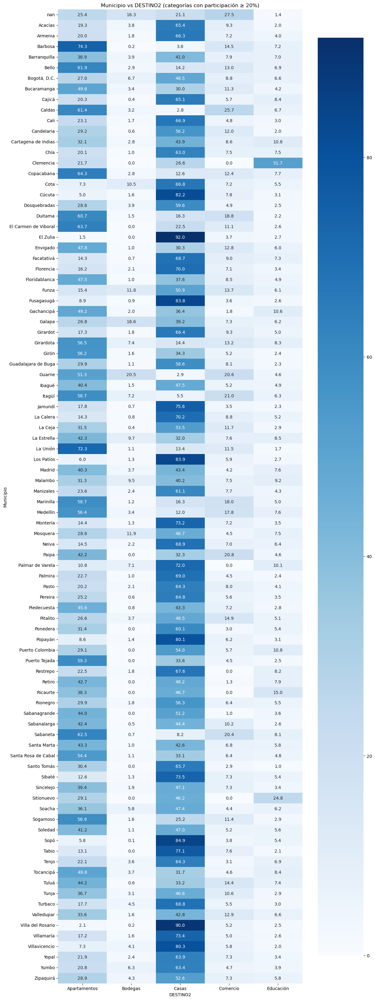


Tabla cruzada: Municipio vs ESTADO_ACT


ESTADO_ACT,En proceso,Paralizada completa,Paralizada incompleta,Suspendida
Municipio,,,,
NaN,50.02,35.64,0.58,3.90
Acacías,32.23,53.31,1.60,0.00
Armenia,25.23,48.31,4.67,12.16
Barbosa,30.19,47.57,2.66,8.57
Barranquilla,30.22,45.28,2.60,11.80
Bello,42.51,38.00,1.10,4.63
"Bogotá, D.C.",42.01,32.24,3.54,8.07
Bucaramanga,30.37,42.54,1.91,14.86
Cajicá,42.18,32.25,4.16,10.02


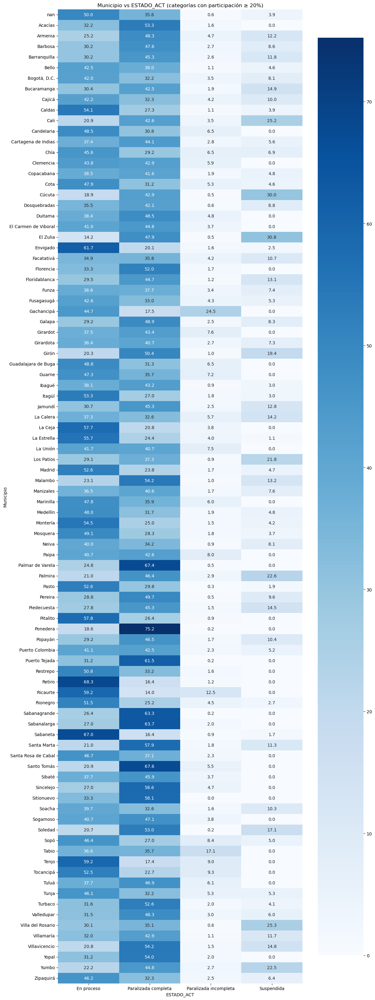


Tabla cruzada: Municipio vs MOVIMIENTO


MOVIMIENTO,Continúa en estado anterior,Obra nueva,Obra suspendida
Municipio,,,
NaN,65.74,10.87,3.90
Acacías,57.49,15.10,0.00
Armenia,60.91,8.65,12.16
Barbosa,58.38,11.93,8.57
Barranquilla,58.35,10.56,11.80
Bello,56.82,14.36,4.63
"Bogotá, D.C.",54.33,14.47,8.07
Bucaramanga,54.81,10.46,14.86
Cajicá,57.99,12.10,10.02


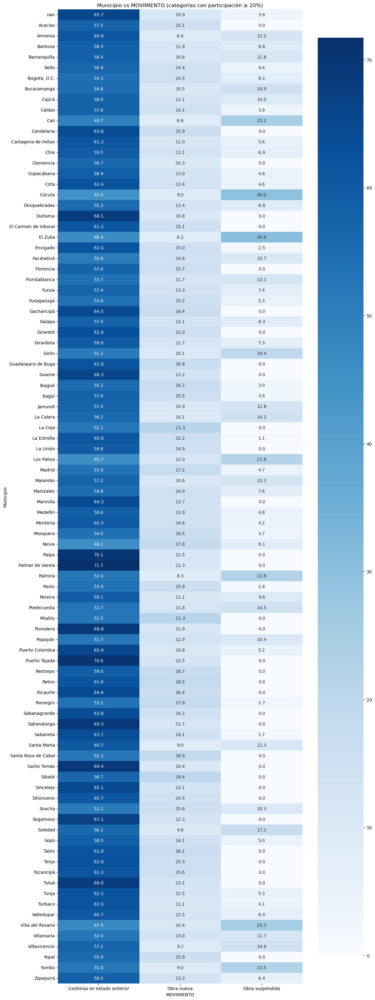


Tabla cruzada: Municipio vs ESTRATO


ESTRATO,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
Municipio,,,,,,
NaN,5.60,24.93,40.89,18.48,4.69,5.40
Acacías,16.95,49.30,30.48,1.56,1.72,0.00
Armenia,20.14,29.22,32.09,6.91,9.66,1.98
Barbosa,0.66,44.17,52.63,2.55,0.00,0.00
Barranquilla,18.36,27.08,32.42,12.40,4.66,5.09
Bello,7.21,24.40,47.47,19.61,1.19,0.13
"Bogotá, D.C.",10.22,35.32,38.96,7.98,3.65,3.88
Bucaramanga,36.66,12.14,29.03,17.63,2.32,2.23
Cajicá,0.81,19.06,50.74,17.18,10.45,1.76


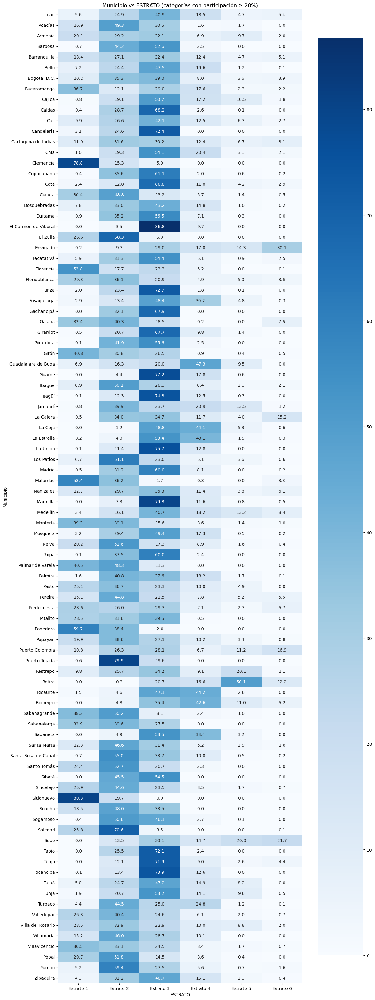


Tabla cruzada: Municipio vs USO


USO,No venta,Sí venta
Municipio,,
NaN,59.85,40.15
Acacías,90.92,9.08
Armenia,81.67,18.33
Barbosa,83.32,16.68
Barranquilla,84.39,15.61
Bello,71.33,28.67
"Bogotá, D.C.",78.57,21.43
Bucaramanga,83.09,16.91
Cajicá,64.85,35.15


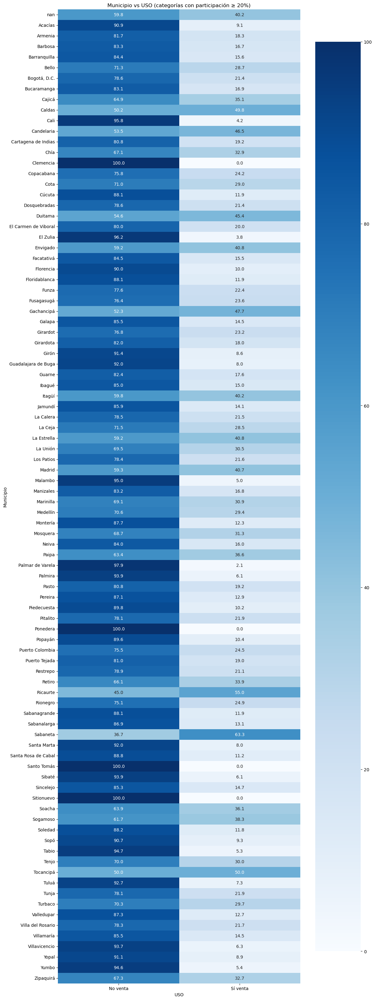


Tabla cruzada: Municipio vs USO_DOS


USO_DOS,Arrendamiento,Uso propio
Municipio,,
NaN,43.40,56.15
Acacías,31.09,68.91
Armenia,13.06,86.57
Barbosa,46.83,52.64
Barranquilla,27.51,72.14
Bello,30.33,68.74
"Bogotá, D.C.",17.33,82.46
Bucaramanga,19.12,80.42
Cajicá,9.88,90.02


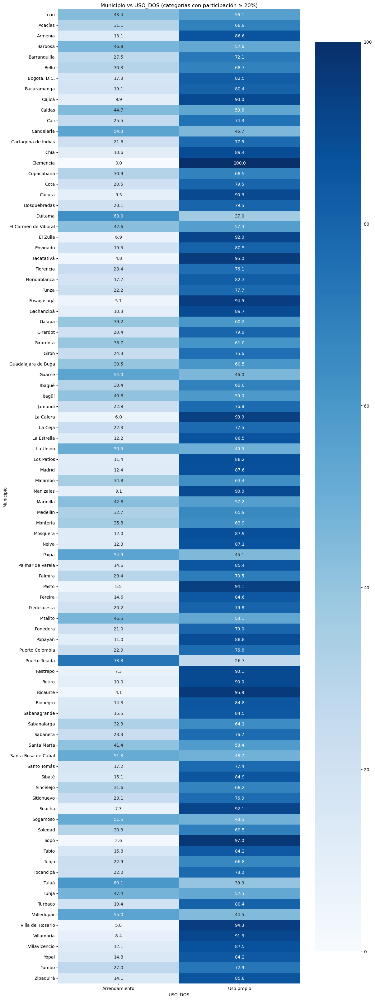


Tabla cruzada: Municipio vs TIPOVRDEST


TIPOVRDEST,No,Sí
Municipio,,
NaN,16.15,83.85
Acacías,8.37,91.63
Armenia,39.64,60.36
Barbosa,26.33,73.67
Barranquilla,27.73,72.27
Bello,17.32,82.68
"Bogotá, D.C.",36.91,63.09
Bucaramanga,40.30,59.70
Cajicá,35.29,64.71


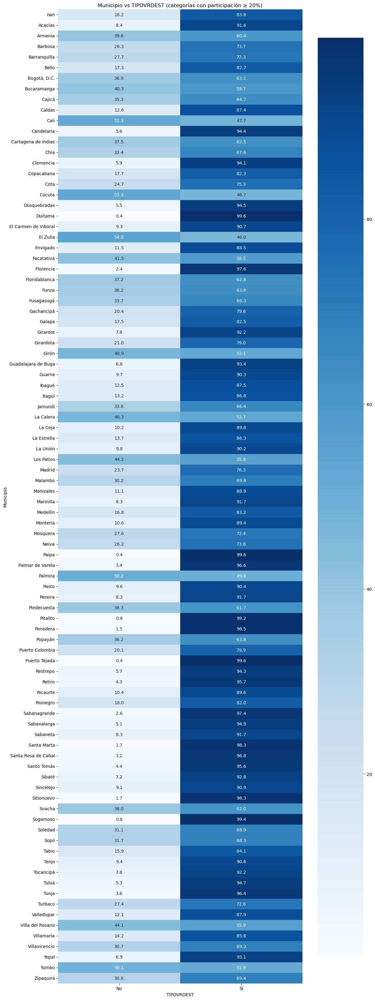


Tabla cruzada: Municipio vs RANVIVI


RANVIVI,Rango 0,Rango 1,Rango 2,Rango 3,Rango 4,Rango 5,Rango 6
Municipio,,,,,,,
NaN,53.45,1.16,4.27,4.02,5.50,17.05,14.55
Acacías,14.88,6.07,27.24,11.44,11.91,24.01,4.46
Armenia,18.12,22.30,16.73,12.53,8.88,13.16,8.27
Barbosa,22.86,0.89,7.38,13.24,12.97,42.08,0.58
Barranquilla,20.96,7.19,13.94,13.16,13.20,22.29,9.26
Bello,23.96,2.59,7.19,10.75,14.15,36.63,4.73
"Bogotá, D.C.",25.17,5.47,7.55,7.99,9.33,27.04,17.45
Bucaramanga,20.66,3.80,16.70,15.99,11.49,23.00,8.36
Cajicá,14.63,0.11,0.98,2.37,6.60,29.19,46.13


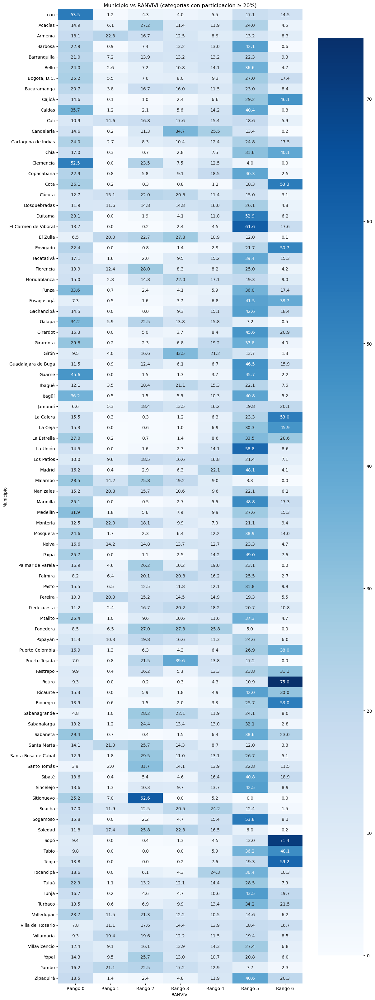


Tabla cruzada: Municipio vs CAPITULO


CAPITULO,Acabados nivel 1,Estructura y cubierta,Mampostería y pañete
Municipio,,,
NaN,17.25,33.14,21.08
Acacías,26.43,19.14,30.02
Armenia,30.43,19.95,27.74
Barbosa,11.31,23.51,48.73
Barranquilla,22.24,22.83,34.44
Bello,13.76,34.22,28.11
"Bogotá, D.C.",12.89,33.87,24.39
Bucaramanga,27.82,18.57,32.50
Cajicá,16.42,33.52,24.98


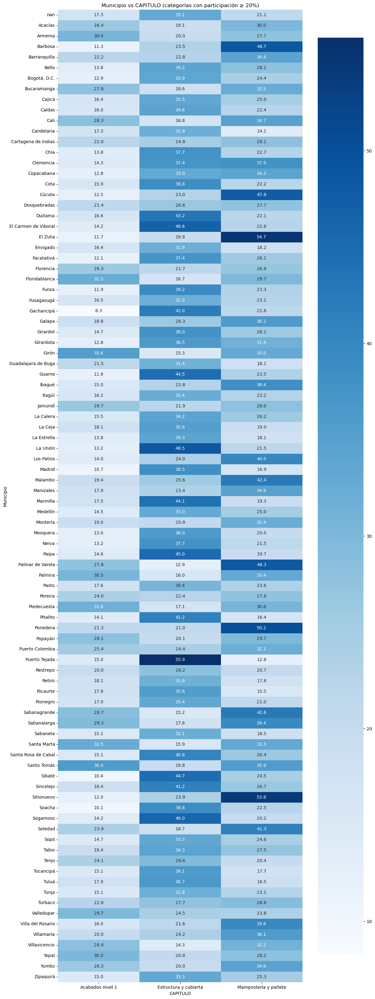

In [136]:
# Umbral mínimo de participación (%)
umbral = 20  # Puedes cambiarlo a 50

# Variables geográficas que queremos conservar
geograficas = ["Departamento", "Municipio"]

# Variables categóricas restantes
otras_categoricas = [
    col for col in categoricas.columns
    if col not in geograficas
]

# Cruces de Departamento y Municipio con las demás variables
for variable_geo in geograficas:

    for variable in otras_categoricas:

        print(f"\nTabla cruzada: {variable_geo} vs {variable}")

        # Tabla cruzada en porcentajes por fila
        tabla = pd.crosstab(
            df_tratado2[variable_geo],
            df_tratado2[variable],
            normalize="index",
            dropna=False
        ) * 100

        # Conservar categorías que alcancen el umbral
        categorias_validas = tabla.columns[
            (tabla >= umbral).any(axis=0)
        ]

        tabla_filtrada = tabla[categorias_validas]

        # Mostrar tabla
        display(tabla_filtrada.round(2))

        # Mapa de calor
        if not tabla_filtrada.empty:

            plt.figure(figsize=(12, max(5, len(tabla_filtrada) * 0.35)))

            sns.heatmap(
                tabla_filtrada,
                annot=True,
                fmt=".1f",
                cmap="Blues"
            )

            plt.title(
                f"{variable_geo} vs {variable} "
                f"(categorías con participación ≥ {umbral}%)"
            )
            plt.xlabel(variable)
            plt.ylabel(variable_geo)
            plt.tight_layout()
            plt.show()


**Para analizar:** ¿Hay categorías dominantes, diferencias entre zonas o grupos y valores escritos de distintas maneras? Las columnas de texto libre pueden tener demasiadas categorías para un gráfico de barras.

## 7. Relaciones entre variables numéricas

Matriz de correlación y mapa de calor. **Interpretar solo variables numéricas con significado cuantitativo:** no confundir códigos o identificadores con relaciones reales.

,ANO_CENSO,CENSO_NUMERO,NUMUNIDEST,NUMUNIVEN,NUMUNIXVEN,UNI_DEC_VIP,UNI_DEC_VIS,UNI_DEC_NOVIS,PRECIOVTAX,AREAVENDIB,AREAVENUNI,AREATOTCO2,NRO_EDIFIC,NRO_PISOS,GRADOAVANC,ANOCULMINA,MESCULMINA
ANO_CENSO,1.000000,0.998386,-0.004752,-0.013882,-0.042120,-0.020196,0.041778,-0.028599,0.349881,-0.031416,-0.009787,-0.025564,-0.027998,0.171499,0.004286,0.531683,-0.069884
CENSO_NUMERO,0.998386,1.000000,-0.004725,-0.013994,-0.042231,-0.020236,0.041909,-0.028641,0.350286,-0.031449,-0.009798,-0.025590,-0.028001,0.171886,0.004681,0.531100,-0.032502
NUMUNIDEST,-0.004752,-0.004725,1.000000,0.377350,0.420541,0.278576,0.585846,0.728758,0.284520,0.635427,-0.028422,0.643418,0.233159,0.628344,-0.000921,-0.002240,0.007495
NUMUNIVEN,-0.013882,-0.013994,0.377350,1.000000,0.162436,0.107038,0.266259,0.240570,0.099687,0.218892,-0.011614,0.213699,0.097126,0.237035,-0.054963,-0.019900,0.006298
NUMUNIXVEN,-0.042120,-0.042231,0.420541,0.162436,1.000000,0.115309,0.174135,0.354882,0.131613,0.292510,-0.011964,0.298595,0.158490,0.214031,-0.041769,-0.014174,0.001367
UNI_DEC_VIP,-0.020196,-0.020236,0.278576,0.107038,0.115309,1.000000,-0.016228,-0.027897,-0.025108,0.149880,-0.083914,0.129727,0.347267,0.060712,0.006278,-0.011977,0.003032
UNI_DEC_VIS,0.041778,0.041909,0.585846,0.266259,0.174135,-0.016228,1.000000,-0.033767,0.111921,0.375767,-0.096277,0.352627,0.147762,0.385939,0.005105,0.019074,0.009258
UNI_DEC_NOVIS,-0.028599,-0.028641,0.728758,0.240570,0.354882,-0.027897,-0.033767,1.000000,0.379639,0.799792,-0.032844,0.807570,0.055664,0.549693,-0.004500,-0.012346,0.002059
PRECIOVTAX,0.349881,0.350286,0.284520,0.099687,0.131613,-0.025108,0.111921,0.379639,1.000000,0.310927,0.081058,0.326163,0.010211,0.397586,0.019112,0.227127,-0.005057
AREAVENDIB,-0.031416,-0.031449,0.635427,0.218892,0.292510,0.149880,0.375767,0.799792,0.310927,1.000000,0.600107,0.963186,0.140374,0.481696,-0.002075,-0.015092,0.004944


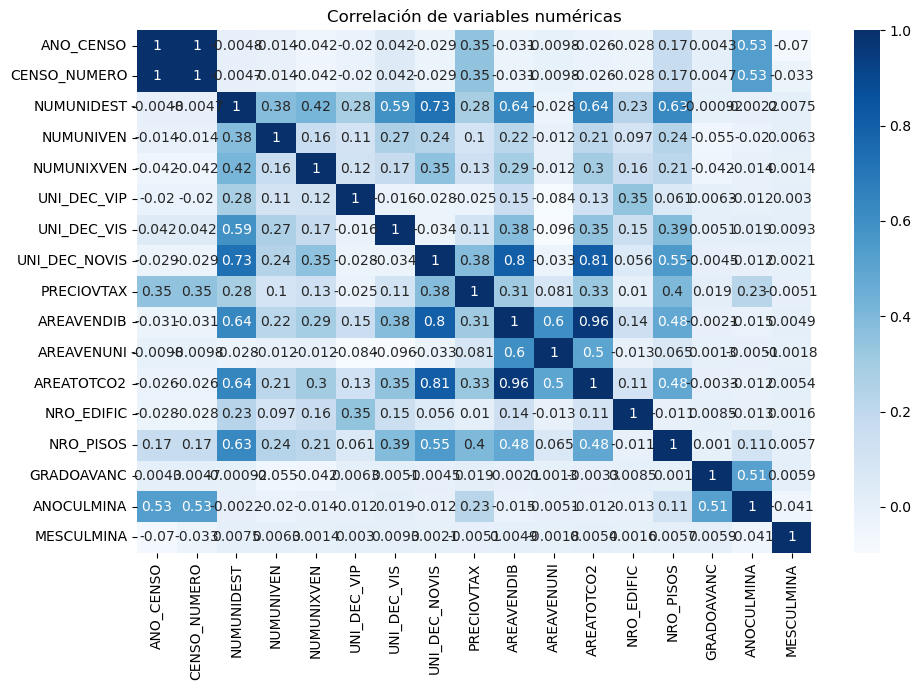

In [137]:
if numericas.shape[1] >= 2:
    correlaciones = numericas.corr()
    display(correlaciones)

    plt.figure(figsize=(10, 7))
    sns.heatmap(correlaciones, cmap="Blues", annot=True)
    plt.title("Correlación de variables numéricas")
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes variables numéricas para calcular correlaciones.")

### Gráfico de dispersión (ejemplo adaptable)

Usamos las dos primeras columnas numéricas como ejemplo. **Antes de interpretar el gráfico, cambia `variable_x` y `variable_y`** si esas columnas son códigos o no tienen una relación de interés.




In [138]:
# Obtener todas las combinaciones de variables numéricas
pares = list(combinations(numericas.columns, 2))

if len(pares) > 0:

    columnas = 3
    filas = math.ceil(len(pares) / columnas)

    fig, axes = plt.subplots(
        filas, columnas,
        figsize=(15, 4 * filas)
    )

    axes = np.array(axes).flatten()

    for i, (variable_x, variable_y) in enumerate(pares):

        axes[i].scatter(
            dfprovisional[variable_x],
            dfprovisional[variable_y],
            alpha=0.3
        )

        axes[i].set_title(f"{variable_x} vs. {variable_y}")
        axes[i].set_xlabel(variable_x)
        axes[i].set_ylabel(variable_y)
        axes[i].grid(alpha=0.3)

    # Eliminar espacios sobrantes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

else:
    print("Se necesitan al menos dos variables numéricas.")